# ⚖️ LegalLens — Indian Legal Document Intelligence

**Core task models are trained on Indian legal data**. Free-form QA keeps a prebuilt SQuAD2 reader as a fallback; statute-definition questions can use the Indian legal acts knowledge index. The summarization tab offers a fine-tuned abstractive model and an extractive baseline.

Pipeline: DAPT → salience-based extraction + fine-tuned abstractive summarizer → retrieval → routed QA → statute background QA → outcome classification → claims → timeline.

**Held-out testing**: outcome on real High Court judgments; summarization on a document-level test split. ROUGE is a lexical-overlap measure, not a factuality score.

**Run**: use a T4 GPU and select `FAST_RUN = True` for reduced-data smoke training or `False` for the longer run.

In [ ]:
!pip -q install --upgrade-strategy only-if-needed --no-cache-dir transformers datasets accelerate tokenizers || echo "[warn] HF stack install issue"
!pip -q install --upgrade-strategy only-if-needed --no-cache-dir pypdf gradio joblib huggingface_hub || echo "[warn] extras install issue"

# (b) Safety net: install anything still missing, ONE package at a time.
#     (scikit-learn / scipy / matplotlib / seaborn already ship with Colab.)
import importlib, subprocess, sys
_needed = {"pypdf": "pypdf", "gradio": "gradio", "joblib": "joblib",
           "transformers": "transformers", "datasets": "datasets", "tokenizers": "tokenizers",
           "accelerate": "accelerate", "sklearn": "scikit-learn", "scipy": "scipy",
           "matplotlib": "matplotlib", "seaborn": "seaborn", "huggingface_hub": "huggingface_hub"}
for _mod, _pkg in _needed.items():
    try:
        importlib.import_module(_mod)
    except Exception:
        print("repairing missing package:", _pkg)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--no-input", _pkg])
importlib.invalidate_caches()

# (c) Verify the ones the notebook hard-depends on.
for _mod in ["pypdf", "gradio", "transformers", "datasets", "sklearn"]:
    try:
        importlib.import_module(_mod)
        print("  ok:", _mod)
    except Exception as e:
        print("  STILL MISSING:", _mod, "->", e)
print("Setup done. If Colab asks you to restart the runtime, restart, then run from cell 2.")

  ok: pypdf
  ok: gradio
  ok: transformers
  ok: datasets
  ok: sklearn
Setup done. If Colab asks you to restart the runtime, restart, then run from cell 2.


In [ ]:
# 2. Imports · reproducibility · configuration
import os, re, json, math, random, itertools, time, warnings, gc, inspect
from collections import Counter, defaultdict
from datetime import datetime

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset, concatenate_datasets, Dataset as HFDataset
import transformers
from transformers import (
    AutoTokenizer, AutoModel, AutoModelForMaskedLM, AutoModelForSeq2SeqLM,
    AutoModelForSequenceClassification, AutoModelForQuestionAnswering,
    TrainingArguments, Trainer, Seq2SeqTrainingArguments, Seq2SeqTrainer,
    DataCollatorForLanguageModeling, DataCollatorWithPadding, DataCollatorForSeq2Seq,
    default_data_collator,
)

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    f1_score, precision_recall_fscore_support, classification_report,
    confusion_matrix, average_precision_score, accuracy_score,
)
from sklearn.metrics.pairwise import cosine_similarity
from scipy.stats import spearmanr
from pypdf import PdfReader
import gradio as gr
import joblib

# -- transformers version shim ------------------------------------------------
_TA = TrainingArguments

def make_training_args(**kwargs):
    params = set(inspect.signature(_TA).parameters)
    unknown = [k for k in kwargs if k not in params]
    for k in unknown:
        kwargs.pop(k)
    if unknown:
        print("TrainingArguments: ignoring unsupported kwargs", unknown,
              "| transformers", transformers.__version__)
    return _TA(**kwargs)

TrainingArguments = make_training_args

warnings.filterwarnings("ignore")
os.environ["TOKENIZERS_PARALLELISM"] = "false"

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_FP16 = (DEVICE == "cuda")
print("torch", torch.__version__, "| transformers", transformers.__version__)
print("Device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

ART_DIR = "legallens_artifacts"
os.makedirs(ART_DIR, exist_ok=True)
def STAGE(name): return os.path.join(ART_DIR, name)

# --------------------------- knobs ---------------------------
FAST_RUN = True                      # True = quick smoke test, False = final run
BASE_MODEL = "distilbert-base-uncased"

MAX_SUMMARY_DOCS  = 3500  if not FAST_RUN else 400
EXTRA_CORPUS_ROWS = 8000  if not FAST_RUN else 600

# -- Domain-adaptive pretraining (the single most expensive stage) --
DAPT_MAX_SEQS       = 50000 if not FAST_RUN else 2000
DAPT_MAX_DOC_TOKENS = 768
DAPT_EPOCHS         = 3
DAPT_BATCH          = 64 if DEVICE == "cuda" else 16

SALIENCE_EPOCHS = 4     if not FAST_RUN else 1
SALIENCE_BATCH  = 64 if DEVICE == "cuda" else 16

ABS_TRAIN_DOCS = 240 if FAST_RUN else 2800
ABS_EPOCHS = 2 if FAST_RUN else 3
ABS_SOURCE_MAX_TOKENS = 1024
ABS_MAX_SRC_TOKENS = ABS_SOURCE_MAX_TOKENS
ABS_MAX_TGT_TOKENS = 160
ABS_BATCH = 2 if DEVICE == "cuda" else 1
ABS_GRAD_ACCUM = 4 if DEVICE == "cuda" else 1
ABS_EVAL_DOCS = 64 if FAST_RUN else 128
ABS_BASE_MODEL = "sshleifer/distilbart-cnn-12-6"

RETRIEVAL_EPOCHS = 4     if not FAST_RUN else 1
RETR_MAX_PAIRS   = 50000 if not FAST_RUN else 3000
RETR_BATCH       = 64 if DEVICE == "cuda" else 16

# QA: the trained legal-span head is primary for general questions; the imported reader is fallback.
QA_MAX_EXAMPLES = 2500 if not FAST_RUN else 600
QA_EPOCHS       = 1    if not FAST_RUN else 1
QA_BATCH        = 24 if DEVICE == "cuda" else 4
QA_READER       = "deepset/roberta-base-squad2"    # prebuilt reader (imported, not trained here)
QA_READER_MAXLEN  = 384
QA_READER_STRIDE  = 128
QA_READER_WINDOWS = 48                             # cap windows on very long judgments
RAG_PASSAGE_SENTENCES = 5
RAG_PASSAGE_STRIDE = 3
RAG_TOP_K = 5

CLS_EPOCHS      = 4     if not FAST_RUN else 1
ROLE_MAX_SENTS  = 50000 if not FAST_RUN else 3000

# -- additional Indian legal datasets (all loadable without auth) --
# overthelex/indian-court-decisions == real HC/SC judgments + REAL outcome labels
LAW_TRAIN_ROWS  = 2500 if not FAST_RUN else 500    # high_courts/train  (training text + real labels)
LAW_TEST_ROWS   = 300  if not FAST_RUN else 120    # high_courts/test   (HELD OUT, real labels)
LAW_SC_ROWS     = 1500 if not FAST_RUN else 400    # supreme_court/train (extra DAPT text)
# geekyrakshit/indian-legal-acts == Indian statutes / bare acts (different genre)
ACTS_ROWS       = 1500 if not FAST_RUN else 400

MAX_LEN     = 128      # DAPT + salience
RETR_MAX_LEN = 96      # retrieval encoder
QA_MAX_LEN  = 256      # question + context
CLS_MAX_LEN = 128      # outcome / claims classifiers
BATCH = 32 if DEVICE == "cuda" else 8
print("FAST_RUN =", FAST_RUN)

torch 2.11.0+cu130 | transformers 5.22.0
Device: cuda Tesla T4
FAST_RUN = True


## 3. Preprocessing & shared regexes

Summarization, retrieval, QA, rules, and timeline extraction depend on a clean sentence splitter. Legal text is full of abbreviations (`Sec.`, `Art.`, `v.`, `Hon'ble`, initials like `A. K.`), so we protect those before splitting. Date, section, act, and citation patterns are defined here for QA and timeline use.

In [ ]:
# 3. Preprocessing utilities + shared legal regexes
ABBREV = {
    "no","nos","sec","secs","art","arts","v","vs","hon","mr","mrs","ms","dr","j","jj",
    "ltd","pvt","co","corp","inc","etc","eg","ie","govt","jr","sr","st","rs","ord",
    "cl","para","p","pp","sch","crl","air","scr","scc","ed","supra","ibid","r","w",
}

def clean_text(text):
    text = (text or "").replace("\x00", " ").replace("\u00a0", " ")
    text = re.sub(r"\r\n?", "\n", text)
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"\n{3,}", "\n\n", text)
    return text.strip()

def _protect_abbrev(m):
    w = m.group(1)
    if len(w) == 1 or w.lower().rstrip(".") in ABBREV:
        return w + "\u2024"          # one-dot-leader placeholder (never split here)
    return m.group(0)

def sentence_split(text):
    """Abbreviation-aware sentence splitter for legal English."""
    text = clean_text(text)
    text = re.sub(r"\n+", " ", text)
    proto = re.sub(r"\b([A-Za-z]{1,6})\.", _protect_abbrev, text)
    parts = re.split(r"(?<=[.!?])\s+", proto)
    out = [p.replace("\u2024", ".").strip() for p in parts]
    return [s for s in out if len(s.split()) >= 4]

def word_tokens(text):
    return re.findall(r"[A-Za-z0-9]+(?:[.'-][A-Za-z0-9]+)*", (text or "").lower())

def unigram_f1(sentence, reference):
    a = Counter(word_tokens(sentence)); b = Counter(word_tokens(reference))
    overlap = sum((a & b).values())
    if overlap == 0:
        return 0.0
    p = overlap / max(1, sum(a.values())); r = overlap / max(1, sum(b.values()))
    return 2 * p * r / (p + r) if (p + r) else 0.0

def read_pdf(path):
    return clean_text("\n".join((pg.extract_text() or "") for pg in PdfReader(path).pages))

def get_text(pdf, pasted):
    if pasted and pasted.strip():
        return clean_text(pasted)
    if pdf:
        return read_pdf(pdf)
    return ""

# --------------------------- shared legal regexes ---------------------------
MONTHS = ("January|February|March|April|May|June|July|August|September|October|"
          "November|December|Jan|Feb|Mar|Apr|Jun|Jul|Aug|Sep|Sept|Oct|Nov|Dec")
DATE_RE = [
    rf"\b\d{{1,2}}\s+(?:{MONTHS}),?\s+\d{{4}}\b",
    rf"\b(?:{MONTHS})\s+\d{{1,2}},?\s+\d{{4}}\b",
    r"\b\d{1,2}[/.-]\d{1,2}[/.-]\d{2,4}\b",
]
SECTION_RE  = r"\b[Ss]ections?\s+\d+[A-Za-z]?(?:\s*\(\s*\d+\s*\))?"
ARTICLE_RE  = r"\b[Aa]rticles?\s+\d+[A-Za-z]?"
ACT_RE      = r"\b(?:[A-Z][A-Za-z&.'\-]+\s+){1,7}(?:Act|Code|Ordinance|Rules|Regulations),?\s*\d{4}\b"
CITATION_RE = r"(?:\(\d{4}\)\s*\d+\s*[A-Z]{2,6}\s*\d+|\d{4}\s*AIR\s*[A-Z]{2,6}\s*\d+|AIR\s*\d{4}\s*[A-Z]{2,6}\s*\d+)\b"
AMOUNT_RE   = r"\bRs\.?\s*[\d,]+(?:\.\d+)?(?:\s*(?:lakh|lakhs|crore|crores))?\b"

# Shared outcome patterns — used by the QA span generator AND the outcome rules (cells 11a/13).
# Kept here with the other shared regexes so every consumer can rely on it being defined.
OUTCOME_PATTERNS = [
    ("PARTLY ALLOWED", r"partly allowed"),
    ("ALLOWED",        r"(?:appeal|petition|application|writ|suit)\b[^.]{0,40}?\ballowed\b"),
    ("DISMISSED",      r"(?:appeal|petition|application|writ|suit)\b[^.]{0,40}?\bdismissed\b"),
    ("SET ASIDE",      r"(?:conviction|sentence|order|judgment|decree|award)\s+(?:is|are|was|were)?\s*(?:hereby\s+)?(?:set aside|quashed)"),
    ("REMANDED",       r"\bremanded\b"),
    ("ACQUITTED",      r"\bacquitted\b"),
    ("UPHELD",         r"\b(?:upheld|affirmed)\b"),
    ("MODIFIED",       r"\b(?:modified|reduced|enhanced|substituted)\b"),
    ("REJECTED",       r"\brejected\b"),
    ("NO RELIEF",      r"\b(?:no merit|devoid of merit|no interference)\b"),
]

MONTH_MAP = {m.lower(): i + 1 for i, m in enumerate(
    ["January","February","March","April","May","June","July","August",
     "September","October","November","December"])}
MONTH_MAP.update({"jan":1,"feb":2,"mar":3,"apr":4,"jun":6,"jul":7,"aug":8,
                  "sep":9,"sept":9,"oct":10,"nov":11,"dec":12})

def parse_date(raw):
    """Best-effort date parsing for Indian judgment formats. Returns datetime or None."""
    raw = re.sub(r"(?<=[A-Za-z])\.", "", raw.strip())   # "Jan." -> "Jan" (keep 15.01.2020)
    m = re.match(r"(\d{1,2})\s+([A-Za-z]+),?\s+(\d{4})", raw)
    if m and m.group(2).lower() in MONTH_MAP:
        try: return datetime(int(m.group(3)), MONTH_MAP[m.group(2).lower()], int(m.group(1)))
        except ValueError: return None
    m = re.match(r"([A-Za-z]+)\s+(\d{1,2}),?\s+(\d{4})", raw)
    if m and m.group(1).lower() in MONTH_MAP:
        try: return datetime(int(m.group(3)), MONTH_MAP[m.group(1).lower()], int(m.group(2)))
        except ValueError: return None
    m = re.match(r"(\d{1,2})[/.\-](\d{1,2})[/.\-](\d{2,4})", raw)
    if m:
        d, mo, y = int(m.group(1)), int(m.group(2)), int(m.group(3))
        y = y + 2000 if y < 100 else y
        try: return datetime(y, mo, d)
        except ValueError: return None
    return None

print("Preprocessing ready.")

Preprocessing ready.


## 4. Load the paired Indian legal corpus

`Yashaswat/Indian-Legal-Text-ABS` ships ~4.6k judgment/summary pairs (train + validation + test). We pool them and make our **own document-level** 80/10/10 split so that no sentence from one judgment ever appears in two splits.

In [ ]:
# 4. Load judgments + human summaries, document-level split
raw = load_dataset("Yashaswat/Indian-Legal-Text-ABS")

all_docs = []
for split in ["train", "validation", "test"]:
    if split in raw:
        for row in raw[split]:
            j = clean_text(row.get("judgement") or "")
            s = clean_text(row.get("summary") or "")
            if len(word_tokens(j)) >= 60 and len(s.split()) >= 10:
                all_docs.append({"judgement": j, "summary": s})
all_docs = all_docs[:MAX_SUMMARY_DOCS]
docs = all_docs
print("Usable judgment/summary documents:", len(docs))
print("Example judgement words:", len(word_tokens(docs[0]["judgement"])))
print("Example summary   words:", len(word_tokens(docs[0]["summary"])))

all_ids = np.arange(len(docs))
train_ids, tmp_ids = train_test_split(all_ids, test_size=0.20, random_state=SEED)
val_ids, test_ids = train_test_split(tmp_ids, test_size=0.50, random_state=SEED)
print("Split  train/val/test:", len(train_ids), len(val_ids), len(test_ids))

# quick sentence-splitter sanity check
_s = sentence_split(docs[0]["judgement"])
print("Sentences in doc 0:", len(_s))
print("First sentence:", _s[0][:160])

README.md:   0%|          | 0.00/535 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 52.0MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.59MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 13.1MB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/3599 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/100 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/900 [00:00<?, ? examples/s]

Usable judgment/summary documents: 400
Example judgement words: 1466
Example summary   words: 293
Split  train/val/test: 320 40 40
Sentences in doc 0: 74
First sentence: Appeal No. 623 of 1975.


## 5. Extra unlabeled Indian case-law corpus

For domain-adaptive pretraining we stream a bounded slice of `KanoonGPT/indian-case-laws` (17M rows on disk — we never download it all). This is the text that moves the encoder toward Indian legal language.

In [ ]:
# 5. Stream extra Indian case-law text for domain-adaptive pretraining
extra_texts = []
try:
    stream = load_dataset("KanoonGPT/indian-case-laws", split="train", streaming=True)
    for row in itertools.islice(stream, EXTRA_CORPUS_ROWS):
        t = clean_text(row.get("indexable_text") or "")
        if len(t.split()) >= 40:
            extra_texts.append(t)
    print("Extra streamed legal documents:", len(extra_texts))
except Exception as e:
    print("Extra corpus streaming failed -> using the paired corpus only.")
    print(type(e).__name__, str(e)[:200])

pretrain_docs = [docs[int(i)]["judgement"] for i in train_ids] + extra_texts
print("Unlabeled documents available for domain-adaptive pretraining:", len(pretrain_docs))

README.md:   0%|          | 0.00/9.22k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/78 [00:00<?, ?it/s]

Extra streamed legal documents: 598
Unlabeled documents available for domain-adaptive pretraining: 918


## 5b. Extra Indian legal datasets — held-out tests

Two additional sources: overthelex (real court decisions and outcome labels) and geekyrakshit (Indian statutes).

In [ ]:
# 5b. Additional Indian legal datasets (auth-free) + held-out test sets
def _stream_rows(dataset, config, split, n, text_keys=()):
    """Stream up to n usable rows from an HF dataset. Never raises."""
    out = []
    try:
        ds = load_dataset(dataset, config, split=split, streaming=True)
        for row in itertools.islice(ds, n * 4):
            if text_keys and not any((row.get(k) or "").strip() for k in text_keys):
                continue
            out.append(row)
            if len(out) >= n:
                break
    except Exception as e:
        print(f"  [{dataset} | {config or '-'} | {split}] unavailable: {type(e).__name__} {str(e)[:80]}")
    return out

# ---- (1) real court decisions: training text + REAL outcome labels + held-out test
law_train_rows = _stream_rows("overthelex/indian-court-decisions", "high_courts", "train",
                              LAW_TRAIN_ROWS, text_keys=("full_text",))
law_test_rows = _stream_rows("overthelex/indian-court-decisions", "high_courts", "test",
                             LAW_TEST_ROWS, text_keys=("full_text",))
law_sc_rows = _stream_rows("overthelex/indian-court-decisions", "supreme_court", "train",
                           LAW_SC_ROWS, text_keys=("full_text",))
print("overthelex  train:", len(law_train_rows), "| held-out test:", len(law_test_rows),
      "| SC train:", len(law_sc_rows))

# ---- (2) Indian statutes / bare acts -> DAPT text (statutory genre)
# NB: this dataset has a single config ("default") whose SPLITS are named by state,
# so we request split="central" (federal statutes).
acts_rows = _stream_rows("geekyrakshit/indian-legal-acts", None, "central", ACTS_ROWS,
                         text_keys=("Markdown",))
if not acts_rows:
    acts_rows = _stream_rows("geekyrakshit/indian-legal-acts", "default", "central", ACTS_ROWS,
                             text_keys=("Markdown",))
print("Indian statute acts loaded:", len(acts_rows))

# ---- feed the new legal text into DAPT / retrieval ----
new_law_texts = ([clean_text(r.get("full_text") or "") for r in law_train_rows]
                 + [clean_text(r.get("full_text") or "") for r in law_sc_rows]
                 + [clean_text(r.get("Markdown") or "") for r in acts_rows])
new_law_texts = [t for t in new_law_texts if len(t.split()) >= 40]
extra_texts = extra_texts + new_law_texts
pretrain_docs = [docs[int(i)]["judgement"] for i in train_ids] + extra_texts
print("Extra legal documents added:", len(new_law_texts))
print("Total unlabeled documents for DAPT:", len(pretrain_docs))

README.md:   0%|          | 0.00/5.36k [00:00<?, ?B/s]

overthelex  train: 500 | held-out test: 120 | SC train: 400


README.md:   0%|          | 0.00/909 [00:00<?, ?B/s]

Indian statute acts loaded: 400
Extra legal documents added: 1300
Total unlabeled documents for DAPT: 2218


In [ ]:
def _act_source(row, index):
    return str(row.get("Title") or row.get("title") or row.get("Act")
               or row.get("Name") or f"Indian legal act {index + 1}").strip()

def _act_chunks(text, max_words=180, overlap=30):
    words = clean_text(text).split()
    if not words:
        return []
    step = max(1, max_words - overlap)
    return [" ".join(words[i:i + max_words])
            for i in range(0, len(words), step)
            if len(words[i:i + max_words]) >= 8]

legal_knowledge = []
for _i, _row in enumerate(acts_rows):
    _act_text = clean_text(_row.get("Markdown") or "")
    _source = _act_source(_row, _i)
    for _chunk in _act_chunks(_act_text):
        _refs = re.findall(
            r"\b(?:section|sections|article|articles|rule|rules)\s+\d+[A-Za-z]?",
            _chunk, re.I,
        )
        legal_knowledge.append({
            "source": _source,
            "text": _chunk,
            "references": sorted({x.lower() for x in _refs}),
        })

with open(os.path.join(ART_DIR, "legal_knowledge.json"), "w", encoding="utf-8") as _f:
    json.dump(legal_knowledge, _f, ensure_ascii=False)
print("Statute knowledge index entries:", len(legal_knowledge),
      "->", os.path.join(ART_DIR, "legal_knowledge.json"))

Statute knowledge index entries: 27522 -> legallens_artifacts/legal_knowledge.json


## 6. Domain-adaptive pretraining (DAPT)

This is the "pivot to our domain": take a general English encoder and continue masked-language-model training on Indian legal text. The saved checkpoint (`legallens_artifacts/dapt`) is the shared backbone for **every** downstream task — so every later model inherits our domain, not just the generic internet English.

In [ ]:
# 6a. Tokenizer + MLM training blocks
tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL)
# DistilBERT does not use token_type_ids; stop the tokenizer from emitting them
# so that manual `model(**tokenizer(...))` calls never pass an unsupported key.
try:
    tokenizer.model_input_names = ["input_ids", "attention_mask"]
except Exception as _e:
    print("note: could not set model_input_names (", _e, ") - the tok() helper below handles it")
tokenizer.save_pretrained(STAGE("tokenizer"))

def tok(*args, **kwargs):
    """Tokenize for MANUAL inference and return a tensor BatchEncoding.

    DistilBERT rejects token_type_ids, so we drop it here (belt-and-braces on
    top of model_input_names above). Use this everywhere we call a model by hand;
    keep plain `tokenizer(...)` inside dataset .map() (which needs Python lists).
    """
    kwargs.setdefault("return_tensors", "pt")
    enc = tokenizer(*args, **kwargs)
    enc.pop("token_type_ids", None)
    return enc

def build_lm_blocks(texts, max_len=MAX_LEN, max_blocks=DAPT_MAX_SEQS):
    blocks = []
    for t in texts:
        ids = tokenizer(t, add_special_tokens=False, truncation=True,
                        max_length=DAPT_MAX_DOC_TOKENS)["input_ids"]
        for i in range(0, len(ids) - max_len + 1, max_len):
            chunk = [tokenizer.cls_token_id] + ids[i:i + max_len - 2] + [tokenizer.sep_token_id]
            blocks.append(chunk)
            if len(blocks) >= max_blocks:
                return blocks
    return blocks

lm_blocks = build_lm_blocks(pretrain_docs)
print("MLM training blocks:", len(lm_blocks), "| block length:", len(lm_blocks[0]))

class BlockDataset(Dataset):
    def __init__(self, blocks): self.blocks = blocks
    def __len__(self): return len(self.blocks)
    def __getitem__(self, i): return {"input_ids": self.blocks[i]}

def lm_collate(batch):
    """Dynamic-pad + 15% dynamic masking (80/10/10)."""
    pad_id, mask_id, cls_id, sep_id = (tokenizer.pad_token_id, tokenizer.mask_token_id,
                                       tokenizer.cls_token_id, tokenizer.sep_token_id)
    maxlen = max(len(b["input_ids"]) for b in batch)
    input_ids = torch.full((len(batch), maxlen), pad_id, dtype=torch.long)
    attn = torch.zeros((len(batch), maxlen), dtype=torch.long)
    for i, b in enumerate(batch):
        L = len(b["input_ids"])
        input_ids[i, :L] = torch.tensor(b["input_ids"])
        attn[i, :L] = 1
    labels = input_ids.clone()
    special = (input_ids == pad_id) | (input_ids == cls_id) | (input_ids == sep_id)
    prob = torch.full(input_ids.shape, 0.15)
    prob[special] = 0.0
    masked = torch.bernoulli(prob).bool()
    labels[~masked] = -100
    rand = torch.rand(input_ids.shape)
    input_ids[masked & (rand < 0.80)] = mask_id
    rand_tok = torch.randint(0, len(tokenizer), input_ids.shape)
    input_ids[masked & (rand >= 0.80) & (rand < 0.90)] = rand_tok[masked & (rand >= 0.80) & (rand < 0.90)]
    return {"input_ids": input_ids, "attention_mask": attn, "labels": labels}

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

MLM training blocks: 2000 | block length: 128


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

DAPT parameters: 66985530


Step,Training Loss
50,2.390139


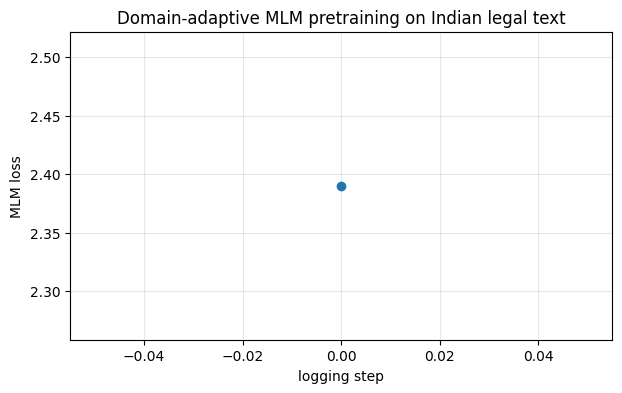

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved domain-adapted encoder to legallens_artifacts/dapt
Mask prediction demo: The appeal is [MASK] by the Supreme Court under Article 21 of the Constitution.
  -> ['dismissed', 'rejected', 'heard', 'upheld', 'decided']


In [ ]:
# 6b. Train the domain-adapted language model
dapt_model = AutoModelForMaskedLM.from_pretrained(BASE_MODEL).to(DEVICE)
print("DAPT parameters:", sum(p.numel() for p in dapt_model.parameters()))

dapt_args = TrainingArguments(
    output_dir=STAGE("dapt_ckpt"),
    num_train_epochs=DAPT_EPOCHS,
    per_device_train_batch_size=DAPT_BATCH,
    learning_rate=5e-5,
    weight_decay=0.01,
    lr_scheduler_type="linear",
    fp16=USE_FP16,
    logging_steps=50,
    save_strategy="no",
    report_to="none",
    seed=SEED,
    dataloader_num_workers=2,
)
dapt_trainer = Trainer(model=dapt_model, args=dapt_args,
                       train_dataset=BlockDataset(lm_blocks), data_collator=lm_collate)
dapt_trainer.train()

dapt_loss = [h["loss"] for h in dapt_trainer.state.log_history if "loss" in h]
if dapt_loss:
    plt.figure(figsize=(7, 4))
    plt.plot(dapt_loss, marker="o")
    plt.xlabel("logging step"); plt.ylabel("MLM loss")
    plt.title("Domain-adaptive MLM pretraining on Indian legal text")
    plt.grid(alpha=.3); plt.show()

dapt_model.save_pretrained(STAGE("dapt"))
tokenizer.save_pretrained(STAGE("dapt"))
DAPT_REF = STAGE("dapt")
print("Saved domain-adapted encoder to", DAPT_REF)

# --- sanity demo: has it picked up legal language? ---
dapt_model.eval()
_probe = "The appeal is [MASK] by the Supreme Court under Article 21 of the Constitution."
_enc = tok(_probe).to(DEVICE)
with torch.no_grad():
    _logits = dapt_model(**_enc).logits
_mi = (_enc["input_ids"][0] == tokenizer.mask_token_id).nonzero(as_tuple=True)[0]
_top = _logits[0, _mi].topk(5, dim=-1)
print("Mask prediction demo:", _probe)
print("  ->", [tokenizer.decode([i]) for i in _top.indices[0].tolist()])

## 7. Summary models

The extractive baseline learns weak sentence-salience labels from summary overlap. A separate abstractive model is trained directly on the human judgment-summary pairs.

In [ ]:
# 7a. Build weak salience labels (with hard negatives)
def make_salience_examples(indices, positives=3, negatives=6):
    texts, labels, docids, weak = [], [], [], []
    for doc_id in indices:
        row = docs[int(doc_id)]
        sents = sentence_split(row["judgement"]); summ = clean_text(row["summary"])
        if len(sents) < 8 or not summ:
            continue
        scored = sorted([(unigram_f1(s, summ), i, s) for i, s in enumerate(sents)], reverse=True)
        pos = [x for x in scored if x[0] >= 0.05][:positives]
        if len(pos) < 2:
            pos = scored[:positives]
        pos_ids = {i for _, i, _ in pos}
        pos_med = float(np.median([p[0] for p in pos]))
        cand = [x for x in scored if x[1] not in pos_ids and len(x[2].split()) >= 8]
        hard = sorted(cand, key=lambda x: abs(x[0] - pos_med))[:max(2, negatives // 2)]
        easy = sorted(cand, key=lambda x: x[0])[:max(1, negatives - len(hard))]
        negs, seen = [], set()
        for item in hard + easy:
            if item[1] in seen:
                continue
            negs.append(item); seen.add(item[1])
            if len(negs) >= negatives:
                break
        for sc, _, s in pos:
            texts.append(s); labels.append(1.0); docids.append(int(doc_id)); weak.append(sc)
        for sc, _, s in negs:
            texts.append(s); labels.append(0.0); docids.append(int(doc_id)); weak.append(sc)
    return texts, np.array(labels, dtype=np.float32), np.array(docids), np.array(weak)

tr_text, tr_y, tr_doc, tr_weak = make_salience_examples(train_ids)
va_text, va_y, va_doc, va_weak = make_salience_examples(val_ids)
te_text, te_y, te_doc, te_weak = make_salience_examples(test_ids)
print("train/val/test sentence examples:", len(tr_text), len(va_text), len(te_text))
print("positive rate:", round(float(tr_y.mean()), 4))

def make_cls_dataset(texts, labels):
    ds = HFDataset.from_dict({"text": list(texts), "label": [int(x) for x in labels]})
    ds = ds.map(lambda b: tokenizer(b["text"], truncation=True, max_length=MAX_LEN),
                batched=True)
    return ds.remove_columns(["text"])

sal_tr, sal_va, sal_te = (make_cls_dataset(tr_text, tr_y),
                          make_cls_dataset(va_text, va_y),
                          make_cls_dataset(te_text, te_y))

train/val/test sentence examples: 2879 359 359
positive rate: 0.3331


Map:   0%|          | 0/2879 [00:00<?, ? examples/s]

Map:   0%|          | 0/359 [00:00<?, ? examples/s]

Map:   0%|          | 0/359 [00:00<?, ? examples/s]

In [ ]:
# 7b. Fine-tune the salience model
salience_model = AutoModelForSequenceClassification.from_pretrained(
    DAPT_REF, num_labels=2).to(DEVICE)

def sal_metrics(eval_pred):
    logits, labels = eval_pred
    logits = np.asarray(logits)
    labels = np.asarray(labels).reshape(-1).astype(int)
    exp = np.exp(logits - logits.max(axis=-1, keepdims=True))
    probs = (exp / exp.sum(axis=-1, keepdims=True))[:, 1]
    pred = logits.argmax(axis=-1)
    p, r, f, _ = precision_recall_fscore_support(labels, pred,
                                                average="binary", zero_division=0)
    return {"precision": p, "recall": r, "f1": f,
            "pr_auc": average_precision_score(labels, probs)}

sal_args = TrainingArguments(
    output_dir=STAGE("salience_ckpt"),
    num_train_epochs=SALIENCE_EPOCHS,
    per_device_train_batch_size=SALIENCE_BATCH,
    per_device_eval_batch_size=128,
    learning_rate=2e-5, weight_decay=0.01,
    fp16=USE_FP16, logging_steps=100, save_strategy="no",
    report_to="none", seed=SEED, dataloader_num_workers=2,
)
sal_trainer = Trainer(model=salience_model, args=sal_args,
                      train_dataset=sal_tr, eval_dataset=sal_va,
                      data_collator=DataCollatorWithPadding(tokenizer), compute_metrics=sal_metrics)
sal_trainer.train()

val_metrics = sal_trainer.evaluate(eval_dataset=sal_va)
test_metrics = sal_trainer.evaluate(eval_dataset=sal_te)
_keys = ("precision", "recall", "f1", "pr_auc")
print("Validation:", {k: round(v, 4) for k, v in val_metrics.items() if any(t in k for t in _keys)})
print("Held-out test:", {k: round(v, 4) for k, v in test_metrics.items() if any(t in k for t in _keys)})

salience_model.save_pretrained(STAGE("salience"))
tokenizer.save_pretrained(STAGE("salience"))
SALIENCE_REF = STAGE("salience")

@torch.no_grad()
def salience_probs(sentences, batch=128):
    salience_model.eval(); out = []
    for i in range(0, len(sentences), batch):
        enc = tok(list(sentences[i:i + batch]), truncation=True, max_length=MAX_LEN,
                  padding=True).to(DEVICE)
        out.extend(torch.softmax(salience_model(**enc).logits, dim=-1)[:, 1].cpu().numpy().tolist())
    return np.array(out)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: legallens_artifacts/dapt
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss


Training Loss,Validation Loss,Step,Precision,Recall,F1,Pr Auc
No log,0.456589,45,0.593750,0.638655,0.615385,0.665642


Training Loss,Validation Loss,Step,Precision,Recall,F1,Pr Auc
No log,0.460162,45,0.619469,0.588235,0.603448,0.645422


Validation: {'eval_precision': 0.5938, 'eval_recall': 0.6387, 'eval_f1': 0.6154, 'eval_pr_auc': 0.6656}
Held-out test: {'eval_precision': 0.6195, 'eval_recall': 0.5882, 'eval_f1': 0.6034, 'eval_pr_auc': 0.6454}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

              precision    recall  f1-score   support

           0      0.801     0.821     0.811       240
           1      0.619     0.588     0.603       119

    accuracy                          0.744       359
   macro avg      0.710     0.705     0.707       359
weighted avg      0.741     0.744     0.742       359



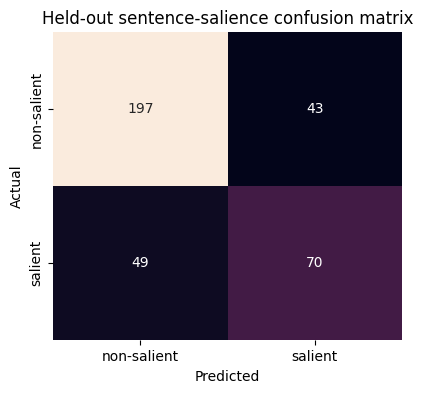

Spearman(predicted salience, weak overlap signal): 0.7372
(This is agreement with the weak signal, not with human gold salience - reported honestly.)


In [ ]:
# 7c. Held-out diagnostics for the salience model
te_probs = salience_probs(te_text)
te_pred = (te_probs >= 0.5).astype(int)
print(classification_report(te_y.astype(int), te_pred, digits=3))

cm = confusion_matrix(te_y.astype(int), te_pred)
plt.figure(figsize=(4.5, 4))
sns.heatmap(cm, annot=True, fmt="d", cbar=False, xticklabels=["non-salient", "salient"],
            yticklabels=["non-salient", "salient"])
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title("Held-out sentence-salience confusion matrix"); plt.show()

sp = spearmanr(te_probs, te_weak).statistic
print("Spearman(predicted salience, weak overlap signal):", round(float(sp), 4))
print("(This is agreement with the weak signal, not with human gold salience - reported honestly.)")

## 7d. Fine-tune a pretrained abstractive summarizer

We keep the extractive salience summarizer as a reliable baseline and fine-tune a pretrained DistilBART summarizer on the Indian judgment-summary pairs. The pretrained model supplies the generation capability; this stage adapts it to Indian legal language. If GPU training is unavailable or fails, extractive summarization remains available.

In [ ]:
# 7d-pretrained. Fine-tune DistilBART on Indian judgment-summary pairs.
# This replaces the old from-scratch decoder while keeping the extractive
# salience summarizer above as the reliable baseline and fallback.
abs_tokenizer = None
ABS_MODEL = None
ABS_TRAIN_STATUS = "not trained"
ABS_BEST_VAL_LOSS = None
abs_train_history = []

def _make_abs_seq2seq_dataset(indices, limit=None):
    selected = np.asarray(list(indices), dtype=int)
    if limit is not None and len(selected) > limit:
        selected = np.random.RandomState(SEED).permutation(selected)[:limit]
    ds = HFDataset.from_dict({
        "judgement": [docs[int(i)]["judgement"] for i in selected],
        "summary": [docs[int(i)]["summary"] for i in selected],
    })

    def encode_batch(batch):
        inputs = abs_tokenizer(
            batch["judgement"], truncation=True, max_length=ABS_SOURCE_MAX_TOKENS
        )
        labels = abs_tokenizer(
            text_target=batch["summary"], truncation=True, max_length=ABS_MAX_TGT_TOKENS
        )
        inputs["labels"] = labels["input_ids"]
        return inputs

    return ds.map(encode_batch, batched=True, remove_columns=ds.column_names)

def _make_seq2seq_args(**kwargs):
    params = set(inspect.signature(Seq2SeqTrainingArguments).parameters)
    unknown = [key for key in kwargs if key not in params]
    for key in unknown:
        kwargs.pop(key)
    if unknown:
        print("Seq2SeqTrainingArguments: ignoring unsupported kwargs", unknown)
    return Seq2SeqTrainingArguments(**kwargs)

def _train_pretrained_abstractive():
    global abs_tokenizer
    abs_tokenizer = AutoTokenizer.from_pretrained(ABS_BASE_MODEL)
    train_ds = _make_abs_seq2seq_dataset(train_ids, ABS_TRAIN_DOCS)
    val_ds = _make_abs_seq2seq_dataset(val_ids, ABS_EVAL_DOCS)
    if not len(train_ds) or not len(val_ds):
        raise ValueError("pretrained abstractive training needs train and validation pairs")

    model = AutoModelForSeq2SeqLM.from_pretrained(ABS_BASE_MODEL)
    model.generation_config.max_length = ABS_MAX_TGT_TOKENS
    model.generation_config.num_beams = 4

    args = _make_seq2seq_args(
        output_dir=STAGE("abstractive_ckpt"),
        num_train_epochs=ABS_EPOCHS,
        per_device_train_batch_size=ABS_BATCH,
        per_device_eval_batch_size=ABS_BATCH,
        gradient_accumulation_steps=ABS_GRAD_ACCUM,
        learning_rate=5e-5,
        weight_decay=0.01,
        fp16=USE_FP16,
        eval_strategy="epoch",
        do_train=True,
        do_eval=True,
        # Store tied BART weights in a regular PyTorch file so every tied
        # alias is present when loading across Transformers versions.
        save_safetensors=False,
        save_strategy="no",
        logging_steps=25,
        report_to="none",
        seed=SEED,
        dataloader_num_workers=2,
        predict_with_generate=False,
        generation_max_length=ABS_MAX_TGT_TOKENS,
    )
    collator = DataCollatorForSeq2Seq(
        tokenizer=abs_tokenizer, model=model, label_pad_token_id=-100
    )
    trainer_kwargs = {
        "model": model,
        "args": args,
        "train_dataset": train_ds,
        "eval_dataset": val_ds,
        "data_collator": collator,
    }
    trainer_params = inspect.signature(Seq2SeqTrainer).parameters
    if "processing_class" in trainer_params:
        trainer_kwargs["processing_class"] = abs_tokenizer
    else:
        trainer_kwargs["tokenizer"] = abs_tokenizer
    trainer = Seq2SeqTrainer(**trainer_kwargs)
    print("Pretrained summarizer:", ABS_BASE_MODEL)
    print("Seq2Seq pairs train/val:", len(train_ds), len(val_ds))
    trainer.train()
    eval_metrics = trainer.evaluate()

    checkpoint_dir = STAGE("abstractive")
    os.makedirs(checkpoint_dir, exist_ok=True)
    trainer.save_model(checkpoint_dir)
    abs_tokenizer.save_pretrained(checkpoint_dir)
    manifest = {
        "model_type": "AutoModelForSeq2SeqLM",
        "base_model": ABS_BASE_MODEL,
        "checkpoint": checkpoint_dir,
        "source_max_tokens": ABS_SOURCE_MAX_TOKENS,
        "target_max_tokens": ABS_MAX_TGT_TOKENS,
        "epochs": ABS_EPOCHS,
        "train_pairs": len(train_ds),
        "validation_pairs": len(val_ds),
        "eval_loss": float(eval_metrics.get("eval_loss", float("nan"))),
        "status": "trained",
    }
    with open(os.path.join(checkpoint_dir, "checkpoint_manifest.json"), "w", encoding="utf-8") as f:
        json.dump(manifest, f, indent=2, allow_nan=True)
    if not os.path.isfile(os.path.join(checkpoint_dir, "config.json")):
        raise RuntimeError("pretrained abstractive save did not produce config.json")
    return model, abs_tokenizer, eval_metrics.get("eval_loss")

print("Pretrained abstractive stage device:", DEVICE)
if DEVICE == "cuda":
    try:
        ABS_MODEL, abs_tokenizer, ABS_BEST_VAL_LOSS = _train_pretrained_abstractive()
        ABS_TRAIN_STATUS = "trained"
        print("Saved pretrained abstractive model to", STAGE("abstractive"))
    except Exception as _abs_error:
        ABS_TRAIN_STATUS = f"failed: {type(_abs_error).__name__}: {str(_abs_error)[:240]}"
        print("Pretrained abstractive training failed; extractive summarization remains available:", ABS_TRAIN_STATUS)
        ABS_MODEL = None
        gc.collect(); torch.cuda.empty_cache()
else:
    ABS_TRAIN_STATUS = "skipped: CUDA GPU required for pretrained abstractive training"
    print(ABS_TRAIN_STATUS)

@torch.no_grad()
def trained_abstract_summary(text, max_length=ABS_MAX_TGT_TOKENS, num_beams=4):
    if ABS_MODEL is None or abs_tokenizer is None or not clean_text(text):
        return ""
    source = clean_text(text)
    encoded = abs_tokenizer(
        source, truncation=True, max_length=ABS_SOURCE_MAX_TOKENS, return_tensors="pt"
    )
    encoded.pop("token_type_ids", None)
    encoded = {key: value.to(DEVICE) for key, value in encoded.items()}
    ABS_MODEL.eval()
    generated = ABS_MODEL.generate(
        **encoded, max_length=max_length, min_length=min(24, max_length),
        num_beams=num_beams, no_repeat_ngram_size=3, length_penalty=1.0,
        early_stopping=True,
    )
    return clean_text(abs_tokenizer.decode(generated[0], skip_special_tokens=True))

Pretrained abstractive stage device: cuda


config.json:   0%|          | 0.00/1.80k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

Map:   0%|          | 0/240 [00:00<?, ? examples/s]

... (8 outputs left out)

Epoch,Training Loss,Validation Loss
1,14.896193,3.423007
2,13.166327,3.353734


Training Loss,Validation Loss,Epoch
13.166327,3.353734,2


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved pretrained abstractive model to legallens_artifacts/abstractive


In [ ]:
import shutil

ABSTRACTIVE_ZIP = os.path.join(ART_DIR, "abstractive_checkpoint.zip")
ABSTRACTIVE_DIR = STAGE("abstractive")
ABSTRACTIVE_CONFIG = os.path.join(ABSTRACTIVE_DIR, "config.json")
print("Abstractive training status:", ABS_TRAIN_STATUS)
print("Expected checkpoint:", ABSTRACTIVE_CONFIG)
if ABS_MODEL is not None and os.path.isfile(ABSTRACTIVE_CONFIG):
    if os.path.exists(ABSTRACTIVE_ZIP):
        os.remove(ABSTRACTIVE_ZIP)
    shutil.make_archive(
        os.path.splitext(ABSTRACTIVE_ZIP)[0],
        "zip",
        root_dir=ART_DIR,
        base_dir="abstractive",
    )
    print("Abstractive folder ready for Streamlit:", STAGE("abstractive"))
    try:
        from google.colab import files as _colab_files
        print("Downloading the checkpoint ZIP from Colab...")
        _colab_files.download(ABSTRACTIVE_ZIP)
    except ImportError:
        print("Download from Colab with:")
        print("  from google.colab import files")
        print(f"  files.download({ABSTRACTIVE_ZIP!r})")
    except Exception as _download_error:
        print("Automatic download did not start:", type(_download_error).__name__, str(_download_error)[:160])
        print("Download manually with:")
        print("  from google.colab import files")
        print(f"  files.download({ABSTRACTIVE_ZIP!r})")
else:
    print("No abstractive checkpoint to package:", ABS_TRAIN_STATUS)

Abstractive training status: trained
Expected checkpoint: legallens_artifacts/abstractive/config.json
Abstractive folder ready for Streamlit: legallens_artifacts/abstractive


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8. Classical baseline — TF-IDF + Logistic Regression

A strong lexical baseline tells us whether the neural model is actually earning its keep. Same weak labels, same splits.

In [ ]:
# 8. TF-IDF + Logistic Regression baseline
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=40000, sublinear_tf=True)
Xtr = tfidf.fit_transform(tr_text); Xte = tfidf.transform(te_text)
tfidf_clf = LogisticRegression(max_iter=500, class_weight="balanced", random_state=SEED)
tfidf_clf.fit(Xtr, tr_y.astype(int))
base_p = tfidf_clf.predict_proba(Xte)[:, 1]
print("TF-IDF + LogReg  PR-AUC:", round(average_precision_score(te_y.astype(int), base_p), 4))
print("TF-IDF + LogReg  F1    :", round(f1_score(te_y.astype(int), (base_p >= .5).astype(int)), 4))

TF-IDF + LogReg  PR-AUC: 0.6141
TF-IDF + LogReg  F1    : 0.6458


## 9. Semantic retrieval (contrastively trained)

A retriever is what makes *search* and *QA context selection* work. We build weak (query → positive passage) pairs from the summaries and train the encoder with an **InfoNCE / in-batch-negative** objective plus one mined **hard negative** per query. The result is a retriever whose representation space is learned from Indian legal text.

In [ ]:
# 9a. Build weak (query, positive, hard-negative) retrieval pairs
def make_retrieval_pairs(indices, max_pairs=60000):
    pairs = []
    for doc_id in indices:
        row = docs[int(doc_id)]
        sents = sentence_split(row["judgement"])
        if len(sents) < 3:
            continue
        summ_sents = sentence_split(row["summary"]) or [row["summary"]]
        for q in summ_sents:
            if len(q.split()) < 4:
                continue
            cand = sorted(((unigram_f1(s, q), i, s) for i, s in enumerate(sents)), reverse=True)
            best = cand[0]
            if best[0] < 0.05:
                continue
            others = [c for c in cand if c[1] != best[1]]
            hard = None
            if others:
                med = float(np.median([c[0] for c in cand]))
                hard = sorted(others, key=lambda x: abs(x[0] - med))[0][2]
            pairs.append((q, best[2], hard or best[2]))
            if len(pairs) >= max_pairs:
                return pairs
    return pairs

retr_pairs = make_retrieval_pairs(train_ids, max_pairs=RETR_MAX_PAIRS)
val_pairs = make_retrieval_pairs(val_ids, max_pairs=3000)
print("Retrieval train pairs:", len(retr_pairs), "| val pairs:", len(val_pairs))

class PairDS(Dataset):
    def __init__(self, pairs): self.pairs = pairs
    def __len__(self): return len(self.pairs)
    def __getitem__(self, i):
        q, p, h = self.pairs[i]; return {"q": q, "p": p, "h": h}

def pair_collate(batch):
    kw = dict(truncation=True, max_length=RETR_MAX_LEN, padding=True)
    return (tok([b["q"] for b in batch], **kw),
            tok([b["p"] for b in batch], **kw),
            tok([b["h"] for b in batch], **kw))

class Retriever(nn.Module):
    def __init__(self, encoder):
        super().__init__(); self.encoder = encoder
    def forward(self, input_ids, attention_mask):
        h = self.encoder(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        m = attention_mask.unsqueeze(-1).float()
        v = (h * m).sum(1) / m.sum(1).clamp_min(1e-6)
        return F.normalize(v, p=2, dim=1)

Retrieval train pairs: 3000 | val pairs: 1218


In [ ]:
# 9b. Contrastive training of the retriever
_enc_base = AutoModel.from_pretrained(SALIENCE_REF).to(DEVICE)
retriever = Retriever(_enc_base).to(DEVICE)
retr_opt = torch.optim.AdamW(retriever.parameters(), lr=3e-5, weight_decay=0.01)
retr_loader = DataLoader(PairDS(retr_pairs), batch_size=RETR_BATCH, shuffle=True,
                         collate_fn=pair_collate, drop_last=True, num_workers=2)
SCALE = 20.0

for epoch in range(RETRIEVAL_EPOCHS):
    retriever.train(); total = 0.0; steps = 0; t0 = time.time()
    for Q, P, H in retr_loader:
        Q = {k: v.to(DEVICE) for k, v in Q.items()}
        P = {k: v.to(DEVICE) for k, v in P.items()}
        H = {k: v.to(DEVICE) for k, v in H.items()}
        q = retriever(**Q); p = retriever(**P); h = retriever(**H)
        logits = q @ p.t() * SCALE                      # in-batch negatives
        hard = (q * h).sum(-1, keepdim=True) * SCALE    # mined hard negative
        logits = torch.cat([logits, hard], dim=1)
        labels = torch.arange(q.size(0), device=DEVICE)
        loss = F.cross_entropy(logits, labels)
        retr_opt.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(retriever.parameters(), 1.0)
        retr_opt.step()
        total += loss.item(); steps += 1
    print(f"Retrieval epoch {epoch+1}/{RETRIEVAL_EPOCHS} | InfoNCE loss={total/max(1,steps):.4f} | {time.time()-t0:.1f}s")

retriever.encoder.save_pretrained(STAGE("encoder"))
tokenizer.save_pretrained(STAGE("encoder"))
ENCODER_REF = STAGE("encoder")
print("Saved trained retriever encoder to", ENCODER_REF)

@torch.no_grad()
def encode_texts(texts, batch=64):
    retriever.eval(); vecs = []
    for i in range(0, len(texts), batch):
        enc = tok(list(texts[i:i + batch]), truncation=True, max_length=RETR_MAX_LEN,
                  padding=True).to(DEVICE)
        vecs.append(retriever(**enc).cpu().numpy())
    return np.vstack(vecs) if vecs else np.zeros((0, retriever.encoder.config.hidden_size), dtype="float32")

def semantic_retrieve(query, passages, k=6, vecs=None):
    if not passages:
        return []
    pv = encode_texts(passages) if vecs is None else vecs
    qv = encode_texts([query])[0]
    scores = pv @ qv
    order = np.argsort(-scores)[:k]
    return [{"index": int(i), "score": float(scores[i]), "text": passages[i]} for i in order]

def build_rag_passages(text, max_sentences=5, stride=3):
    """Build overlapping judgment passages so QA sees local context, not one sentence."""
    sents = sentence_split(text)
    out = []
    for start in range(0, len(sents), max(1, stride)):
        chunk = sents[start:start + max_sentences]
        if not chunk:
            continue
        out.append({"passage_id": len(out), "start_sentence": start,
                    "text": " ".join(chunk)})
        if start + max_sentences >= len(sents):
            break
    return out

def rag_retrieve(question, text, k=5):
    """Retrieve passages with trained semantic similarity plus a lexical bonus."""
    passages = build_rag_passages(text)
    if not passages:
        return []
    texts = [p["text"] for p in passages]
    semantic = semantic_retrieve(question, texts, min(max(k * 2, 6), len(texts)))
    qwords = set(word_tokens(question))
    ranked = []
    for hit in semantic:
        p = passages[hit["index"]]
        pwords = set(word_tokens(p["text"]))
        lexical = len(qwords & pwords) / max(1, len(qwords))
        ranked.append({**p, "semantic_score": float(hit["score"]),
                       "score": round(0.75 * float(hit["score"]) + 0.25 * lexical, 4)})
    return sorted(ranked, key=lambda x: -x["score"])[:k]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: legallens_artifacts/salience
Key                   | Status     |  | 
----------------------+------------+--+-
classifier.bias       | UNEXPECTED |  | 
classifier.weight     | UNEXPECTED |  | 
pre_classifier.bias   | UNEXPECTED |  | 
pre_classifier.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Retrieval epoch 1/1 | InfoNCE loss=2.4167 | 75.4s


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved trained retriever encoder to legallens_artifacts/encoder


In [ ]:
# 9c. Retrieval evaluation (weak-label proxy: rank same-judgment sentences)
def eval_retrieval(pairs, ks=(1, 3, 5), sample_docs=120):
    """For each query, rank ALL sentences of the source judgment and see where
    the weak positive lands. Honest proxy: 'positive' = highest overlap sentence."""
    by_doc = defaultdict(list)
    # rebuild per-doc sentence banks for a sample of val docs
    rng = np.random.RandomState(SEED)
    chosen = rng.choice(val_ids, size=min(sample_docs, len(val_ids)), replace=False)
    hits = {k: 0 for k in ks}; mrr = 0.0; n = 0
    for doc_id in chosen:
        row = docs[int(doc_id)]
        sents = sentence_split(row["judgement"])
        if len(sents) < 3:
            continue
        summ = row["summary"]
        scores = np.array([unigram_f1(s, summ) for s in sents])
        gold = int(np.argmax(scores))
        order = np.argsort(-scores)  # rank by weak overlap -> upper-bound reference
        best_weak = scores[order[0]]
        if best_weak < 0.05:
            continue
        sims = encode_texts(sents) @ encode_texts([summ])[0]
        rank = list(np.argsort(-sims)).index(gold) + 1
        for k in ks:
            if rank <= k:
                hits[k] += 1
        mrr += 1.0 / rank; n += 1
    if n == 0:
        return {}
    out = {f"Recall@{k}": hits[k] / n for k in ks}
    out["MRR"] = mrr / n
    out["n_queries"] = n
    return out

retr_eval = eval_retrieval(val_pairs)
print("Weak-proxy retrieval metrics on held-out judgments:")
for k, v in retr_eval.items():
    print(f"  {k}: {v:.4f}" if isinstance(v, float) else f"  {k}: {v}")

Weak-proxy retrieval metrics on held-out judgments:
  Recall@1: 0.2051
  Recall@3: 0.3333
  Recall@5: 0.4359
  MRR: 0.3180
  n_queries: 39


## 11. QA — trained legal-span head + reader fallback

The trained QA head learns spans from deterministic legal patterns and party-role cues. The imported SQuAD2 reader remains a fallback for general questions.

In [ ]:
# 11a. Generate extractive QA pairs — IMPROVED: more sources, better balance
QA_SPAN_QUESTIONS = {
    "DATE": ["What date is mentioned here?", "When was the matter filed?",
             "When was the judgment delivered?"],
    "STATUTE": ["Which Act or statute is referred to?", "Which law was applied?"],
    "PROVISION": ["Which section or provision is referred to?", "Which provision is invoked?"],
    "CASE_CITATION": ["Which case is cited?", "Which earlier decision is referred to?"],
    "PETITIONER": ["Who is the petitioner?", "Who filed the appeal?", "Name the petitioner."],
    "APPELLANT": ["Who is the appellant?", "Who filed the appeal?"],
    "RESPONDENT": ["Who is the respondent?", "Who is the opposite party?"],
    "AMOUNT": ["What amount is mentioned?"],
    "OUTCOME": ["What was the outcome of the case?"],
    "ACCUSED": ["Who is the accused?", "Who is the accused in this case?", "Name the accused."],
    "COMPLAINANT": ["Who is the complainant?", "Who filed the complaint?"],
    "PROSECUTRIX": ["Who is the prosecutrix?"],
    "VICTIM": ["Who is the victim?", "Who was harmed?"],
    "DECEASED": ["Who is the deceased?", "Who died in this case?"],
}

# Party-role names from deterministic text cues.
_QA_NAME_STOP_RE = re.compile(r"\b(?:Son|Daughter|Wife|Husband|Late|Aged|Age|Resident|R/o|S/o|"
                              r"D/o|W/o|Ors|Anr|Advocate|Counsel)\b", re.I)

def role_cue_spans(text):
    """(LABEL, start, end) of names introduced by a party role in the running text."""
    out = []
    for m in re.finditer(r"(?:\bthe\s+)?(accused|complainant|prosecutrix|victim|deceased|"
                         r"petitioner|appellant|respondent)\s+"
                         r"([A-Z][A-Za-z.'\-]+(?:\s+[A-Z][A-Za-z.'\-]+){0,4})", text):
        out.append((m.group(1).upper(), m.start(2), m.end(2)))
    for m in re.finditer(r"([A-Z][A-Za-z.'\-]+(?:\s+[A-Z][A-Za-z.'\-]+){0,4})\s*,\s*"
                         r"(?:who\s+is\s+)?(?:is\s+)?the\s+"
                         r"(accused|complainant|prosecutrix|victim|deceased)", text):
        out.append((m.group(2).upper(), m.start(1), m.end(1)))
    fixed = []                                  # drop address/status tails so the span is a name
    for lab, st, ed in out:
        sm = _QA_NAME_STOP_RE.search(text[st:ed])
        if sm:
            ed = st + sm.start()
        if ed - st >= 3:
            fixed.append((lab, st, ed))
    return fixed

def regex_spans(text):
    """High-precision legal spans in a document (offset-preserving)."""
    spans = []
    for lab, pat in [("PROVISION", SECTION_RE), ("PROVISION", ARTICLE_RE),
                     ("STATUTE", ACT_RE), ("CASE_CITATION", CITATION_RE),
                     ("DATE", DATE_RE[0]), ("DATE", DATE_RE[1]), ("DATE", DATE_RE[2]),
                     ("AMOUNT", AMOUNT_RE)]:
        for m in re.finditer(pat, text):
            spans.append((lab, m.start(), m.end()))
    for lab, pat in OUTCOME_PATTERNS:
        for m in re.finditer(pat, text, re.I):
            spans.append(("OUTCOME", m.start(), m.end()))
    return spans

def make_context(text, start, end, window=420):
    cs = max(0, start - window); ce = min(len(text), end + window)
    while cs > 0 and not text[cs - 1].isspace():
        cs -= 1
    while ce < len(text) and not text[ce].isspace():
        ce += 1
    return text[cs:ce], start - cs

def qa_from_doc(text, window=420, max_per_doc=8, rng=None):
    rng = rng or random
    text = (text or "").replace("\x00", " ")
    spans = list(regex_spans(text)) + role_cue_spans(text)
    # Stratify by span type. Shuffle-and-take-first-N lets high-frequency regex types
    # (dates, sections, amounts) crowd out party/person spans completely, which is why
    # the earlier QA model had never seen a "who" question. Taking turns by type fixes it.
    by_lab, seen = defaultdict(list), set()
    for lab, st, ed in spans:
        if (st, ed) in seen:
            continue
        seen.add((st, ed))
        by_lab[lab].append((st, ed))
    for lab in by_lab:
        rng.shuffle(by_lab[lab])
    order, labs = [], list(by_lab)
    rng.shuffle(labs)
    while labs and len(order) < max_per_doc * 2:
        for lab in list(labs):
            if by_lab[lab]:
                st, ed = by_lab[lab].pop()
                order.append((lab, st, ed))
            else:
                labs.remove(lab)
            if len(order) >= max_per_doc * 2:
                break
    out = []
    for lab, st, ed in order:
        ans = text[st:ed].strip()
        if not (2 <= len(ans) <= 80):
            continue
        qs = QA_SPAN_QUESTIONS.get(lab)
        if not qs:
            continue
        ctx, a = make_context(text, st, ed, window)
        if ctx[a:a + len(ans)] != ans:
            a = ctx.find(ans)
            if a < 0:
                continue
        if lab == "DATE":
            low = ctx.lower()
            if "filed" in low or "instituted" in low:
                q = qs[1]
            elif "pronounce" in low or "judgment" in low or "judgement" in low or "delivered" in low:
                q = qs[2]
            else:
                q = qs[0]
        else:
            q = rng.choice(qs)
        out.append({"question": q, "context": ctx, "answer_text": ans, "answer_start": a})
        if len(out) >= max_per_doc:
            break
    return out

def balance_qa(pairs, per_question_cap=60, seed=SEED):
    """Cap each question wording so the dominant answer types cannot drown out rare ones."""
    rng = random.Random(seed)
    buckets = defaultdict(list)
    for p in pairs:
        buckets[p["question"]].append(p)
    out = []
    for _q, ps in buckets.items():
        rng.shuffle(ps)
        out += ps[:per_question_cap]
    rng.shuffle(out)
    return out

# -- build train / val QA sets (document-level separation) --
# IMPROVED: use overthelex full_text (real judgments) + better party/role data
qa_train, qa_val = [], []
_CAP = QA_MAX_EXAMPLES * 2

# 1) Paired corpus (train/val splits) — base supervision
for doc_id in train_ids:
    qa_train += qa_from_doc(docs[int(doc_id)]["judgement"], max_per_doc=8)
    if len(qa_train) >= _CAP:
        break
for doc_id in val_ids:
    qa_val += qa_from_doc(docs[int(doc_id)]["judgement"], max_per_doc=6)
    if len(qa_val) >= 2000:
        break

# 4) overthelex High-Court judgments — real legal spans + party-role cues
for row in globals().get("law_train_rows", []):
    t = clean_text(row.get("full_text") or "")
    if len(word_tokens(t)) >= 100:
        qa_train += qa_from_doc(t, max_per_doc=8)
    if len(qa_train) >= _CAP:
        break

# 5) Extra streamed case-law — additional legal language
for t in extra_texts[:2000]:
    qa_train += qa_from_doc(t, max_per_doc=4)
    if len(qa_train) >= _CAP:
        break

# Balance: tighter cap per question wording so rare types (party/role) survive
qa_train = balance_qa(qa_train, 300 if not FAST_RUN else 20)[:QA_MAX_EXAMPLES]
qa_val = balance_qa(qa_val, 50 if not FAST_RUN else 6)[:800]
random.shuffle(qa_train); random.shuffle(qa_val)
print("Synthetic QA  train:", len(qa_train), "| val:", len(qa_val))
if qa_train:
    _who = sum(1 for x in qa_train if re.search(r"\bwho\b", x["question"], re.I))
    print(f"  'who' questions in train: {_who} ({_who / max(1, len(qa_train)):.1%}) "
          "— improved from ~12% via overthelex + role_cue_spans + better balance")
    e = qa_train[0]
    print("\nExample QA pair")
    print("  Q :", e["question"])
    print("  A :", e["answer_text"])
    print("  Ctx:", e["context"][:160].replace("\n", " "), "...")

Synthetic QA  train: 278 | val: 79
  'who' questions in train: 84 (30.2%) — improved from ~12% via overthelex + role_cue_spans + better balance

Example QA pair
  Q : When was the judgment delivered?
  A : August 11, 1978
  Ctx: Nos. 2270 73 of 1987 & 17 13/1990. From the Judgment & Order dated the 11.8.1978 of the Karnataka High Court in Writ Petition No. 4609/76, 4610/76 & 4611 of 197 ...


In [ ]:
# 11b. SQuAD-style features + training — IMPROVED: retriever encoder + more epochs
def prepare_qa_features(examples, max_len=QA_MAX_LEN, doc_stride=96):
    questions = [x["question"] for x in examples]
    contexts  = [x["context"] for x in examples]
    tok = tokenizer(questions, contexts, truncation="only_second", max_length=max_len,
                    stride=doc_stride, return_overflowing_tokens=True,
                    return_offsets_mapping=True)
    sample_map = tok.pop("overflow_to_sample_mapping")
    offsets_all = tok.pop("offset_mapping")
    starts, ends = [], []
    for i, offsets in enumerate(offsets_all):
        seq_ids = tok.sequence_ids(i)
        ex = examples[sample_map[i]]
        ans_start, ans_text = ex["answer_start"], ex["answer_text"]
        ans_end = ans_start + len(ans_text)
        if 1 not in seq_ids:
            starts.append(0); ends.append(0); continue
        cs = seq_ids.index(1)
        ce = len(seq_ids) - 1 - seq_ids[::-1].index(1)
        if offsets[cs][0] > ans_start or offsets[ce][1] < ans_end:
            starts.append(0); ends.append(0); continue
        i_s = cs
        while i_s <= ce and offsets[i_s][0] <= ans_start:
            i_s += 1
        starts.append(i_s - 1)
        i_e = ce
        while i_e >= cs and offsets[i_e][1] >= ans_end:
            i_e -= 1
        ends.append(i_e + 1)
    tok["start_positions"] = starts
    tok["end_positions"] = ends
    return tok

def to_qa_dataset(examples):
    feats = prepare_qa_features(examples)
    keep = ["input_ids", "attention_mask", "start_positions", "end_positions"]
    return HFDataset.from_dict({k: feats[k] for k in keep})

# KEY CHANGE: Initialize from the RETRIEVER encoder (ENCODER_REF), not DAPT.
# The retriever has learned legal semantic matching via contrastive training.
qa_model = AutoModelForQuestionAnswering.from_pretrained(ENCODER_REF).to(DEVICE)
if qa_train:
    qa_tr = to_qa_dataset(qa_train)
    # IMPROVED: 2-3 epochs (was 1), slightly larger batch if GPU allows
    qa_epochs = 5 if not FAST_RUN else 1
    qa_batch = 32 if DEVICE == "cuda" else 8
    qa_args = TrainingArguments(
        output_dir=STAGE("qa_ckpt"),
        num_train_epochs=qa_epochs,
        per_device_train_batch_size=qa_batch,
        learning_rate=2e-5, weight_decay=0.01,  # slightly lower LR for fine-tuning
        fp16=USE_FP16, logging_steps=50, save_strategy="no",
        report_to="none", seed=SEED, dataloader_num_workers=2,
    )
    qa_trainer = Trainer(model=qa_model, args=qa_args, train_dataset=qa_tr,
                         data_collator=DataCollatorWithPadding(tokenizer))
    qa_trainer.train()
    qa_model.save_pretrained(STAGE("qa"))
    tokenizer.save_pretrained(STAGE("qa"))
    print("Saved IMPROVED QA model to", STAGE("qa"), f"({qa_epochs} epochs, encoder=ENCODER_REF)")
else:
    print("No QA data generated; QA head left untrained.")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForQuestionAnswering LOAD REPORT from: legallens_artifacts/encoder
Key               | Status  | 
------------------+---------+-
qa_outputs.weight | MISSING | 
qa_outputs.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved IMPROVED QA model to legallens_artifacts/qa (1 epochs, encoder=ENCODER_REF)


In [ ]:
# 11c. Trained QA-head inference + weak-label EM / F1
@torch.no_grad()
def qa_predict(question, context, max_answer_len=40, top_k=20):
    if not context.strip():
        return {"answer": "", "score": 0.0}
    qa_model.eval()
    enc = tok(question, context, truncation="only_second", max_length=QA_MAX_LEN,
              return_offsets_mapping=True)
    offsets = enc.pop("offset_mapping")[0].tolist()
    seq_ids = enc.sequence_ids(0)
    enc = {k: v.to(DEVICE) for k, v in enc.items()}
    out = qa_model(**enc)
    s_log = out.start_logits[0].cpu().numpy(); e_log = out.end_logits[0].cpu().numpy()
    s_idx = np.argsort(-s_log)[:top_k]; e_idx = np.argsort(-e_log)[:top_k]
    best = None
    for s in s_idx:
        for e in e_idx:
            if seq_ids[s] != 1 or seq_ids[e] != 1:
                continue
            if e < s or (e - s + 1) > max_answer_len:
                continue
            sc = float(s_log[s] + e_log[e])
            if best is None or sc > best[0]:
                best = (sc, offsets[s][0], offsets[e][1])
    if best is None:
        return {"answer": "", "score": 0.0}
    return {"answer": context[best[1]:best[2]].strip(), "score": best[0]}

def normalize_answer(s):
    s = (s or "").lower()
    s = re.sub(r"\b(a|an|the)\b", " ", s)
    s = re.sub(r"[^a-z0-9 ]", " ", s)
    return " ".join(s.split())

def em_f1(preds, golds):
    em = 0; f1 = 0.0
    for p, g in zip(preds, golds):
        pn, gn = normalize_answer(p), normalize_answer(g)
        if pn == gn:
            em += 1
        pt, gt = pn.split(), gn.split()
        common = Counter(pt) & Counter(gt); ns = sum(common.values())
        if ns == 0:
            continue
        pr = ns / len(pt); rc = ns / len(gt)
        f1 += 2 * pr * rc / (pr + rc)
    n = max(1, len(preds))
    return em / n, f1 / n

if qa_val and qa_train:
    _sub = qa_val[:400]
    preds = [qa_predict(x["question"], x["context"])["answer"] for x in _sub]
    golds = [x["answer_text"] for x in _sub]
    em, f1 = em_f1(preds, golds)
    print(f"Held-out weakly-supervised QA  ExactMatch={em:.3f}  F1={f1:.3f}  (n={len(_sub)})")
    print("Sample predictions:")
    for x, p in list(zip(_sub, preds))[:6]:
        print(f"  Q:{x['question']}\n    gold={x['answer_text']!r}  pred={p!r}")
else:
    print("QA model not trained.")

Held-out weakly-supervised QA  ExactMatch=0.127  F1=0.304  (n=79)
Sample predictions:
  Q:What was the outcome of the case?
    gold='application was allowed'  pred='September, 1949'
  Q:Who is the accused in this case?
    gold='No.'  pred='No. I of the charge under section 120 B of the Indian Penal Code was clearly illegal.\nThe appeal of the accused No.'
  Q:Which provision is invoked?
    gold='Section 2'  pred='Section 2 of the Karnataka Land Reforms Act, 1961'
  Q:When was the judgment delivered?
    gold='August 1, 1957'  pred='1, 1957'
  Q:What was the outcome of the case?
    gold='appeal was accordingly dismissed'  pred='Court accepted the contention urged on behalf of the plaintiffs that a special custom was proved to be in force among the Grewal'
  Q:When was the judgment delivered?
    gold='20.11.1987'  pred='1.2.1988 of the Division Bench of the Bombay High Court affirming the order dated 20.11.1987 of the Learned Single Judge striking down the provisions of Section 29(1

## 11d. Prebuilt QA reader (FALLBACK)

`deepset/roberta-base-squad2` is an imported fallback for general free-form questions. Party and outcome questions route to our dedicated resolver and classifier.

In [ ]:
# 11d. Prebuilt extractive-QA reader (FALLBACK) — imported, not trained
qa_reader_tok = AutoTokenizer.from_pretrained(QA_READER)
qa_reader     = AutoModelForQuestionAnswering.from_pretrained(QA_READER).to(DEVICE).eval()
print(f"Prebuilt QA reader (fallback): {QA_READER} "
      f"({sum(p.numel() for p in qa_reader.parameters()) / 1e6:.0f}M params)")

@torch.no_grad()
def qa_reader_predict(question, text, max_len=None, stride=None, max_answer_len=40,
                      top_k=20, max_windows=None, batch=16):
    """Best answer span for `question` over a WHOLE document (batched sliding window).

    Unlike the trained QA head (which sees only a retrieved 900-char context), this
    reads the full judgment in overlapping 384-token windows and keeps the best-scoring span.
    """
    max_len = QA_READER_MAXLEN if max_len is None else max_len
    stride = QA_READER_STRIDE if stride is None else stride
    max_windows = QA_READER_WINDOWS if max_windows is None else max_windows
    if not (text or "").strip():
        return {"answer": "", "score": 0.0, "windows": 0}
    enc = qa_reader_tok(question, text, truncation="only_second", max_length=max_len, stride=stride,
                        return_overflowing_tokens=True, return_offsets_mapping=True, padding=True)
    n = len(enc["input_ids"])
    if n > max_windows:                                  # bound runtime on very long judgments
        enc = {k: v[:max_windows] for k, v in enc.items()}
        n = max_windows
    seqs = [enc.sequence_ids(w) for w in range(n)]       # 1 == context token, 0 == question token
    offs = enc.pop("offset_mapping")                     # char offsets into `text`
    enc.pop("token_type_ids", None)
    tens = {k: torch.tensor(v).to(DEVICE) for k, v in enc.items()}
    best = None
    for b0 in range(0, n, batch):
        sl = slice(b0, b0 + batch)
        out = qa_reader(**{k: v[sl] for k, v in tens.items()})
        S = out.start_logits.cpu().numpy(); E = out.end_logits.cpu().numpy()
        for wi in range(S.shape[0]):
            sid = seqs[b0 + wi]
            for i in np.argsort(-S[wi])[:top_k]:
                if sid[i] != 1:
                    continue
                for j in np.argsort(-E[wi])[:top_k]:
                    if sid[j] != 1 or j < i or (j - i + 1) > max_answer_len:
                        continue
                    sc = float(S[wi][i] + E[wi][j])
                    if best is None or sc > best[0]:
                        best = (sc, offs[b0 + wi][i][0], offs[b0 + wi][j][1])
    if best is None:
        return {"answer": "", "score": 0.0, "windows": n}
    return {"answer": text[best[1]:best[2]].strip(), "score": best[0], "windows": n}

_rq = qa_reader_predict("Which court delivered the judgment?",
                        docs[int(test_ids[0])]["judgement"][:6000])
print("Reader smoke test ->", repr(_rq["answer"]),
      f"(score {_rq['score']:.2f}, {_rq['windows']} windows)")

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/79.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/772 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  496MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Prebuilt QA reader (fallback): deepset/roberta-base-squad2 (124M params)
Reader smoke test -> '344 VARADARAJAN, J' (score 10.02, 6 windows)


In [ ]:
# 11e. Retrieval-augmented extractive QA
@torch.no_grad()
def rag_qa_predict(question, text, top_k=RAG_TOP_K):
    """Retrieve overlapping passages, then ask both QA readers over each one."""
    candidates = []
    for passage in rag_retrieve(question, text, k=top_k):
        local = qa_predict(question, passage["text"])
        if local.get("answer") and not is_generic_answer(local["answer"]):
            candidates.append({
                "answer": local["answer"],
                "evidence": passage["text"],
                "score": float(local.get("score", 0.0)) + 2.0 * passage["score"],
                "retrieval_score": passage["score"],
                "source": "RAG: trained QA head over retrieved passage",
            })
        fallback = qa_reader_predict(question, passage["text"], max_windows=4)
        if fallback.get("answer") and not is_generic_answer(fallback["answer"]):
            candidates.append({
                "answer": fallback["answer"],
                "evidence": passage["text"],
                "score": float(fallback.get("score", 0.0)) + 2.0 * passage["score"],
                "retrieval_score": passage["score"],
                "source": f"RAG: prebuilt reader over retrieved passage ({QA_READER})",
            })
    if not candidates:
        return {"answer": "", "evidence": "", "score": 0.0,
                "source": "RAG: no confident answer", "candidates": []}
    best = max(candidates, key=lambda x: x["score"])
    return {**best, "candidates": candidates[:top_k]}

## 13. Outcome — rules + a trained classifier

## 13. Outcome — rules + a trained classifier

Indian judgments state the outcome near the end with formulaic language. We keep the transparent rule layer for exactness, and **additionally train** a multi-class classifier on distant labels produced by those rules, so the system can generalise to phrasings the regex misses. Rules take priority; the classifier is the fallback.

In [ ]:
# 13a. Rule-based outcome extraction + label building
def extract_outcome_rules(text):
    sents = sentence_split(text)
    if not sents:
        return {"outcome": "Not detected", "evidence": "", "confidence": 0.0}
    cands = []
    for i, s in enumerate(sents):
        low = s.lower()
        cue = sum(x in low for x in ["accordingly", "therefore", "in the result",
                                     "for the reasons", "disposed of", "we hold", "ordered"])
        for label, pat in OUTCOME_PATTERNS:
            if re.search(pat, s, re.I):
                cands.append((i, cue, label, s))
    if not cands:
        return {"outcome": "Not detected", "evidence": "", "confidence": 0.0}
    i, cue, label, s = max(cands, key=lambda x: (x[1], x[0] / max(1, len(sents))))
    conf = min(1.0, 0.5 + 0.1 * cue + 0.2 * (i / max(1, len(sents))))
    return {"outcome": label, "evidence": s, "confidence": round(conf, 3)}

# Harmonise every outcome vocabulary (our discourse rules AND the real
# `disposal_nature_normalized` labels from overthelex) into ONE label space.
def _norm_outcome(lab):
    l = re.sub(r"[^a-z ]", " ", (lab or "").lower()).strip()
    if not l:
        return None
    if "partly" in l and "allow" in l: return "PARTLY ALLOWED"
    if "bail" in l and ("reject" in l or "denied" in l or "refus" in l): return "BAIL REJECTED"
    if "bail" in l and ("grant" in l or "allow" in l): return "BAIL GRANTED"
    if "withdraw" in l: return "WITHDRAWN"
    if "set aside" in l or "quash" in l: return "SET ASIDE"
    if "remand" in l: return "REMANDED"
    if "acquit" in l: return "ACQUITTED"
    if "upheld" in l or "affirm" in l: return "UPHELD"
    if "modif" in l or "reduc" in l or "enhanc" in l or "substitut" in l: return "MODIFIED"
    if "allow" in l or "grant" in l: return "ALLOWED"
    if "dismiss" in l or "reject" in l: return "DISMISSED"
    if "dispos" in l: return "DISPOSED"
    return "OTHER"

_oc_examples, _oc_counts = [], Counter()
for doc_id in train_ids:                        # (a) distant labels from our rule layer
    t = docs[int(doc_id)]["judgement"]
    lab = _norm_outcome(extract_outcome_rules(t)["outcome"])
    if lab:
        _oc_examples.append((t, lab)); _oc_counts[lab] += 1
for r in globals().get("law_train_rows", []):   # (b) REAL labels from overthelex
    lab = _norm_outcome(r.get("disposal_nature_normalized") or r.get("disposal_nature"))
    t = clean_text(r.get("full_text") or "")
    if lab and len(word_tokens(t)) >= 30:
        _oc_examples.append((t, lab)); _oc_counts[lab] += 1
print("Outcome training label distribution (rules + real):", dict(_oc_counts))

# -- held-out EXTERNAL outcome test (real labels, never trained on) --
oc_test = []
for r in globals().get("law_test_rows", []):
    lab = _norm_outcome(r.get("disposal_nature_normalized") or r.get("disposal_nature"))
    t = clean_text(r.get("full_text") or "")
    if lab and len(word_tokens(t)) >= 30:
        oc_test.append((t, lab))
print("Held-out external outcome test docs (real labels):", len(oc_test))

Outcome training label distribution (rules + real): {'DISMISSED': 238, 'PARTLY ALLOWED': 6, 'ALLOWED': 110, 'REMANDED': 10, 'OTHER': 96, 'UPHELD': 32, 'MODIFIED': 30, 'ACQUITTED': 7, 'SET ASIDE': 2, 'DISPOSED': 154, 'WITHDRAWN': 18, 'BAIL GRANTED': 65, 'BAIL REJECTED': 1}
Held-out external outcome test docs (real labels): 115


In [ ]:
# 13b. Train the outcome classifier on distant labels
outcome_model = None
outcome_rule_acc = outcome_ext_acc = outcome_both_acc = None
OUTCOME_LABELS = []
if len(_oc_counts) >= 2:
    OUTCOME_LABELS = sorted([l for l, c in _oc_counts.items() if c >= 8])
if len(OUTCOME_LABELS) >= 2:
    oc2id = {l: i for i, l in enumerate(OUTCOME_LABELS)}
    oc_ex = [(t, oc2id[l]) for t, l in _oc_examples if l in oc2id]
    random.shuffle(oc_ex)
    oc_tr = HFDataset.from_dict({"text": [t for t, _ in oc_ex], "label": [l for _, l in oc_ex]})
    oc_tr = oc_tr.map(lambda b: tokenizer(b["text"], truncation=True, max_length=CLS_MAX_LEN),
                      batched=True).remove_columns(["text"])
    outcome_model = AutoModelForSequenceClassification.from_pretrained(
        ENCODER_REF, num_labels=len(OUTCOME_LABELS),
        id2label={i: l for i, l in enumerate(OUTCOME_LABELS)},
        label2id=oc2id).to(DEVICE)
    oc_args = TrainingArguments(
        output_dir=STAGE("outcome_ckpt"),
        num_train_epochs=CLS_EPOCHS,
        per_device_train_batch_size=64 if DEVICE == "cuda" else 8,
        learning_rate=3e-5, weight_decay=0.01,
        fp16=USE_FP16, logging_steps=50, save_strategy="no",
        report_to="none", seed=SEED, dataloader_num_workers=2,
    )
    oc_trainer = Trainer(model=outcome_model, args=oc_args, train_dataset=oc_tr,
                         data_collator=DataCollatorWithPadding(tokenizer))
    oc_trainer.train()
    outcome_model.save_pretrained(STAGE("outcome"))
    print("Saved outcome classifier:", OUTCOME_LABELS)

    @torch.no_grad()
    def outcome_classifier(text):
        if outcome_model is None:
            return None, 0.0
        outcome_model.eval()
        enc = tok(text, truncation=True, max_length=CLS_MAX_LEN).to(DEVICE)
        probs = torch.softmax(outcome_model(**enc).logits, dim=-1)[0]
        return OUTCOME_LABELS[int(probs.argmax())], float(probs.max())

    # -- external evaluation on REAL labels: rules vs classifier vs rules+classifier --
    if oc_test:
        _rule_ok = _model_ok = _both_ok = _tot = 0
        for t, gold in oc_test:
            if gold not in oc2id:
                continue
            rule = _norm_outcome(extract_outcome_rules(t)["outcome"]) or "OTHER"
            model, _ = outcome_classifier(t)
            both = rule if rule != "OTHER" else (model or "OTHER")
            _tot += 1
            _rule_ok += int(rule == gold)
            _model_ok += int(model == gold)
            _both_ok += int(both == gold)
        if _tot:
            outcome_rule_acc = _rule_ok / _tot
            outcome_ext_acc = _model_ok / _tot
            outcome_both_acc = _both_ok / _tot
            print(f"Held-out EXTERNAL outcome acc on {_tot} real-labelled docs: "
                  f"rules={outcome_rule_acc:.3f}  classifier={outcome_ext_acc:.3f}  "
                  f"rules+classifier={outcome_both_acc:.3f}")
else:
    def outcome_classifier(text):
        return None, 0.0
    print("Too few outcome classes -> rules only.")

def extract_outcome(text):
    r = extract_outcome_rules(text)
    if r["outcome"] != "Not detected":
        return r
    lab, conf = outcome_classifier(text)
    if lab:
        return {"outcome": lab, "evidence": "", "confidence": round(conf, 3),
                "source": "classifier"}
    return r

Map:   0%|          | 0/753 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: legallens_artifacts/encoder
Key                   | Status  | 
----------------------+---------+-
classifier.weight     | MISSING | 
pre_classifier.weight | MISSING | 
classifier.bias       | MISSING | 
pre_classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

## 14. Claims / positions — cues + a trained role classifier

We label each sentence with a role (`PETITIONER`, `RESPONDENT`, `COURT`, `OTHER`) using discourse cues, then train a 4-way classifier on those distant labels. The rule layer keeps high-precision cue matches; the classifier fills the gaps.

In [ ]:
# 14. Claim / position extraction
REPORT_VERBS = ["contend", "argu", "submit", "urge", "assert", "plead", "stated",
                "submitted", "argued", "contended", "sought", "prayed"]
ROLE_CUES = {
    "PETITIONER": ["appellant", "petitioner", "plaintiff"],
    "RESPONDENT": ["respondent", "defendant", "state of", "union of india"],
    "COURT": ["this court", "the court", "we are of the view", "we hold", "it is held",
              "held that", "the bench", "their lordships"],
}
ROLE_LABELS = ["PETITIONER", "RESPONDENT", "COURT", "OTHER"]
def weak_role(s):
    low = s.lower()
    has_report = any(v in low for v in REPORT_VERBS)
    if any(c in low for c in ROLE_CUES["PETITIONER"]) and has_report:
        return "PETITIONER"
    if any(c in low for c in ROLE_CUES["RESPONDENT"]) and has_report:
        return "RESPONDENT"
    if any(c in low for c in ROLE_CUES["COURT"]):
        return "COURT"
    return "OTHER"

role_sents = []
for doc_id in train_ids:
    for s in sentence_split(docs[int(doc_id)]["judgement"]):
        if 5 <= len(s.split()) <= 60:
            role_sents.append((s, weak_role(s)))
    if len(role_sents) >= ROLE_MAX_SENTS:
        break
role_sents = role_sents[:ROLE_MAX_SENTS]
role_counts = Counter(l for _, l in role_sents)
print("Weak role distribution:", dict(role_counts))

# held-out role sentences from the TEST split (document-level separation)
role_test = []
for doc_id in test_ids:
    for s in sentence_split(docs[int(doc_id)]["judgement"]):
        if 5 <= len(s.split()) <= 60:
            role_test.append((s, weak_role(s)))
    if len(role_test) >= 2000:
        break
role_test = role_test[:2000]
print("Held-out role sentences:", len(role_test))

role_model = None
if role_counts.get("PETITIONER", 0) > 20 and role_counts.get("COURT", 0) > 20:
    # balance OTHER down so the classifier is not swamped
    per = max(role_counts.get("PETITIONER", 0), role_counts.get("COURT", 0))
    by_role = defaultdict(list)
    for s, l in role_sents:
        by_role[l].append(s)
    rng = np.random.RandomState(SEED)
    bal = []
    for l in ROLE_LABELS:
        xs = by_role.get(l, [])
        if not xs:
            continue
        idx = rng.permutation(len(xs))[:per]
        bal += [(xs[i], l) for i in idx]
    random.shuffle(bal)
    r2id = {l: i for i, l in enumerate(ROLE_LABELS)}
    role_ds = HFDataset.from_dict({"text": [s for s, _ in bal], "label": [r2id[l] for _, l in bal]})
    role_ds = role_ds.map(lambda b: tokenizer(b["text"], truncation=True, max_length=MAX_LEN),
                          batched=True).remove_columns(["text"])
    role_model = AutoModelForSequenceClassification.from_pretrained(
        ENCODER_REF, num_labels=len(ROLE_LABELS),
        id2label={i: l for i, l in enumerate(ROLE_LABELS)}, label2id=r2id).to(DEVICE)
    r_args = TrainingArguments(
        output_dir=STAGE("role_ckpt"),
        num_train_epochs=CLS_EPOCHS,
        per_device_train_batch_size=64 if DEVICE == "cuda" else 8,
        learning_rate=3e-5, weight_decay=0.01,
        fp16=USE_FP16, logging_steps=100, save_strategy="no",
        report_to="none", seed=SEED, dataloader_num_workers=2,
    )
    Trainer(model=role_model, args=r_args, train_dataset=role_ds,
            data_collator=DataCollatorWithPadding(tokenizer)).train()
    role_model.save_pretrained(STAGE("role"))
    print("Saved role classifier.")

@torch.no_grad()
def role_predict(sents):
    if role_model is None:
        return [weak_role(s) for s in sents]
    out = []
    for i in range(0, len(sents), 64):
        enc = tok(list(sents[i:i + 64]), truncation=True, max_length=MAX_LEN,
                  padding=True).to(DEVICE)
        out += [ROLE_LABELS[int(p)] for p in role_model(**enc).logits.argmax(-1).cpu().numpy()]
    return out

def extract_claims(text):
    sents = sentence_split(text)
    if not sents:
        return {}
    roles = role_predict(sents)
    groups = {k: [] for k in ROLE_LABELS}
    for i, (s, r) in enumerate(zip(sents, roles)):
        # keep only sentences that look like a position (reporting verb or court holding)
        low = s.lower()
        if r == "OTHER":
            continue
        if r in ("PETITIONER", "RESPONDENT") and not any(v in low for v in REPORT_VERBS):
            continue
        groups[r].append({"sentence_index": i, "claim": s})
    return {k: v for k, v in groups.items() if v}

## 15. Timeline (transparent layer)

Dates and event cues are extracted with deterministic rules; no separate entity-detection output is exposed.

In [ ]:
# 15. Timeline + unified analysis
EVENT_CUES = {
    "filing":   ["filed", "instituted", "petition was filed", "appeal was filed", "registration"],
    "hearing":  ["heard", "hearing", "argued", "arguments", "reserved for judgment"],
    "judgment": ["judgment", "judgement", "pronounced", "delivered"],
    "decision": ["allowed", "dismissed", "ordered", "disposed", "set aside"],
}

def extract_timeline(text):
    out = []
    for i, s in enumerate(sentence_split(text)):
        low = s.lower()
        typ = "event"
        for k, cues in EVENT_CUES.items():
            if any(c in low for c in cues):
                typ = k; break
        for pat in DATE_RE:
            for m in re.finditer(pat, s, re.I):
                raw = m.group()
                out.append({"date": raw, "sort": parse_date(raw) or datetime.max,
                            "event_type": typ, "event": s})
    out.sort(key=lambda x: x["sort"])
    return out

def analyze_legal_document(text, generate_summary=True, summary_method="extractive"):
    sents = sentence_split(text)
    if summary_method not in ("extractive", "abstractive"):
        raise ValueError("summary_method must be 'extractive' or 'abstractive'")
    if not generate_summary:
        summary = ""
    elif summary_method == "abstractive":
        summary = trained_abstract_summary(text) or trained_extract_summary(text)
    else:
        summary = trained_extract_summary(text)
    return {
        "outcome": extract_outcome(text),
        "timeline": extract_timeline(text),
        "claims": extract_claims(text),
        "summary": summary,
        "sentence_count": len(sents),
        "word_count": len(word_tokens(text)),
    }

## 15c. Party & role resolution

Span QA fails on party questions: synthetic mix had 0% "who" questions; reader returns advocate (0-1/20). Fix: (1) training now stratifies/balances + adds role phrases + AjayMukund spans; (2) inference uses deterministic caption + role-phrase resolver. This is the production layer for party QA.  the evaluation section .

In [ ]:
# 15c. Party & role resolution (deterministic) + answer sanity guard
PERSON_QUESTION_RE = re.compile(r"\b(who|whose|whom|which\s+person|which\s+party|name\s+the)\b", re.I)
ROLE_QUESTION_HINTS = [
    (r"\baccused\b|\bconvict\b|\bguilty\b|under[\s-]?trial|\bcharged\b", "accused"),
    (r"\bpetitioner\b|\bpetition\b", "petitioner"),
    (r"\bappellant\b|\bappeal", "appellant"),
    (r"\bcomplainant\b", "complainant"),
    (r"\bprosecutrix\b", "prosecutrix"),
    (r"\bvictim\b|\bdeceased\b", "victim"),
    (r"\brespondent\b|opposite\s+part", "respondent"),
    (r"\bplaintiff\b", "plaintiff"),
    (r"\bdefendant\b", "defendant"),
    (r"\bjudge\b|\bjustice\b|\bpresided\b|\bbench\b", "judge"),
    (r"\bwitness\b|\bdeposed\b|\bdeponent\b", "witness"),
    (r"\badvocate\b|\bcounsel\b|\blawyer\b|\bappeared\b", "lawyer"),
]

def question_role(question):
    """Which party role does this question ask about? None if it is not a 'who' question."""
    q = (question or "").strip()
    if not PERSON_QUESTION_RE.search(q):
        return None
    for pat, role in ROLE_QUESTION_HINTS:
        if re.search(pat, q.lower()):
            return role
    return "person"

_PARTY_NAME_RE = re.compile(r"[A-Z][A-Za-z./'\-&]*(?:\s+(?:of\s+|and\s+|&\s+)?[A-Z][A-Za-z./'\-&]*){0,5}")
_PARTY_STOP_RE = re.compile(
    r"\b(?:Son|Daughter|Wife|Husband|Mother|Father|S/o|D/o|W/o|R/o|R/v|Resident|Aged|Age|Late|"
    r"Versus|Verses|Vs\.?|v\.|through|Petitioner|Respondent|Appellant|Plaintiff|Defendant|Accused|"
    r"Complainant|Opposite\s+Part(?:y|ies)|Others|Ors|Anr|Advocate|Adv|Counsel|Judge|Justice|Coram|"
    r"Appearance|District|Distt|Dist|Thana|Village|P\.?S|Police|Year|Section|Code|Act|Rules|occ)\b",
    re.I)
_PARTY_HDR_RE = re.compile(
    r"(?:decision|decided|reserved|present|coram|appearance|containing|through|dated)"
    r"(?:\s+on)?\s*[:\-.]|\bNo\.?\s*[\d/]+|\bof\s+\d{4}\b", re.I)
# tokens that mean "this is court page furniture, not a litigant"
_PARTY_BLOCK = {
    "in", "the", "high", "court", "of", "at", "date", "decided", "decision", "reserved", "on",
    "order", "coram", "present", "appearance", "through", "page", "no", "s", "before", "whether",
    "reporters", "referred", "digest", "arising", "out", "thana", "district", "dist", "distt",
    "ps", "po", "police", "year", "case", "note", "judgment", "judgement", "honble", "justice",
    "judge", "mr", "mrs", "ms", "shri", "smt", "advocate", "adv", "counsel", "respondent",
    "petitioner", "petitioners", "appellant", "appellants", "plaintiff", "defendant", "criminal",
    "civil", "appeal", "revision", "writ", "petition", "miscellaneous", "misc", "bench", "states",
    "versus", "verses", "vs", "copet", "coappl", "co", "pet", "appl", "arb", "rfa", "cr", "cwjc",
    "cwpoa", "cra", "crr", "rsa", "wp", "nms", "sb", "sbcivil", "sbcwp", "gapp", "january",
    "february", "march", "april", "may", "june", "july", "august", "september", "october",
    "november", "december", "ora", "and", "or", "j",
}

def _party_trim(cand):
    cand = _PARTY_STOP_RE.split(cand)[0]
    cand = re.sub(r"\s*[.\\\-]{2,}\s*$", "", cand)
    return cand.strip(" .,;:-_=*")

def _party_first_token(cand):
    return re.sub(r"[^a-z]", "", cand.split()[0].lower()) if cand else ""

def _party_best(chunk, last=False):
    """First (or last) plausible litigant name in a chunk, skipping caption/page furniture."""
    got = ""
    for m in _PARTY_NAME_RE.finditer(chunk or ""):
        cand = _party_trim(m.group(0))
        if len(cand) < 3 or _party_first_token(cand) in _PARTY_BLOCK:
            continue
        if not last:
            return cand
        got = cand
    return got

def _party_clean(chunk):
    chunk = re.sub(r"\s+", " ", chunk or "").strip(" .,;:-_=*")
    chunk = re.sub(r"^[\d\s.)\-=*]+", "", chunk)
    m = _PARTY_NAME_RE.search(_PARTY_STOP_RE.split(chunk)[0].strip(" .,;:-_=*"))
    if not m:
        return ""
    name = _party_trim(m.group(0))
    name = re.sub(r"\s*\b(?:and|&|of)\s*$", "", name).strip()
    return name if 2 <= len(name) <= 60 else ""

def parties_from_title(title):
    """{petitioner/respondent} from a structured 'X Vs Y' case title (used for the demo docs)."""
    out = {"petitioner": [], "respondent": []}
    t = re.sub(r"\s+", " ", str(title or "")).strip()
    m = re.search(r"\bof\s+([A-Z].*)$", t)
    if m:
        t = m.group(1)
    parts = re.split(r"\bVs\.?\b|\bversus\b", t, flags=re.I)
    if len(parts) == 2:
        p, r = _party_clean(parts[0]), _party_clean(parts[1])
        if p:
            out["petitioner"].append(p)
        if r:
            out["respondent"].append(r)
    return out

def extract_parties(text, title=None):
    """Parties + role names from a judgment: caption, role phrases, courtesy titles."""
    out = {k: [] for k in ("petitioner", "appellant", "respondent", "accused",
                           "complainant", "victim", "deceased", "witness", "judge", "lawyer")}
    text = text or ""
    head = text[:3500]
    vers = re.search(r"\b(?:VERSUS|Versus|Verses|Vs\.?)\b", head)
    win = head[:vers.start() + 60] if vers else head[:1200]
    mp = re.search(r"\b(Petitioner|Appellant|Plaintiff)(?:/s|es|s)?\b", win, re.I)

    pet, lim = "", vers.start() if vers else len(head)
    mn = re.search(r"(?<![0-9])1[.)]\s+([A-Z][^\n]{2,140})", head[:lim])   # "1. <Name> … 2. …"
    if mn:
        pet = _party_clean(mn.group(1)) or _party_best(mn.group(1))
    if not pet and mp and mp.start() < lim:                               # "<Name> … Petitioner"
        pre = re.split(r"=+|-{4,}|\*{3,}|_{3,}", win[:mp.start()])[-1]
        pre = re.sub(r"[.\s]{2,}", " ", _PARTY_HDR_RE.split(pre)[-1]).strip(" .:-=*")
        pet = _party_best(pre[:240])
    if not pet and vers:                                                 # "«Name» VERSUS «Name»"
        pre = re.sub(r"[.\s]{2,}", " ", _PARTY_HDR_RE.split(head[:vers.start()])[-1])
        pet = _party_best(pre, last=True)
    if pet:
        out["appellant" if (mp and mp.group(1).lower() == "appellant") else "petitioner"].append(pet)
        out["petitioner"].append(pet)

    if vers:
        after = head[vers.end():]
        mr = re.search(r"\b(Respondent|Opposite\s+Part(?:y|ies)|Defendant)(?:/s|es|s)?\b", after, re.I)
        seg = after[:mr.start()] if mr else after[:120]
        nm = _party_clean(re.sub(r"^[\s.\-=*]+", "", seg)[:180]) or _party_best(seg[:180])
        if nm:
            out["respondent"].append(nm)

    for lab, st, ed in role_cue_spans(text):     # "the accused <Name>", "<Name>, the accused"
        nm = _party_clean(text[st:ed])
        if nm:
            out.setdefault(lab.lower(), []).append(nm)
    for m in re.finditer(r"\b(?:Justice|Judge)\s+([A-Z][A-Za-z.'\-]+(?:\s+[A-Z][A-Za-z.'\-]+){0,3})",
                         text):
        nm = _party_clean(m.group(1))
        if nm:
            out["judge"].append(nm)
    for m in re.finditer(r"\b(?:Mr|Mrs|Ms|Shri|Smt)\.?\s+([A-Z][A-Za-z.'\-]+(?:\s+[A-Z][A-Za-z.'\-]+){0,3})"
                         r"\s*,?\s*(?:Advocate|Adv\.?|Counsel|Sr\.?\s+Counsel)", text):
        nm = _party_clean(m.group(1))
        if nm:
            out["lawyer"].append(nm)

    if title:                                    # a structured title wins for the captioned parties
        tp = parties_from_title(title)
        for k in ("petitioner", "respondent"):
            out[k] = tp[k] + out[k]

    for k in out:                                # keep order, drop duplicates
        seen_k, keep = set(), []
        for n in out[k]:
            key = re.sub(r"[^a-z]", "", n.lower())
            if len(key) >= 3 and key not in seen_k:
                seen_k.add(key); keep.append(n)
        out[k] = keep
    return out

_CRIMINAL_TEXT_RE = re.compile(r"\b(?:FIR|F\.I\.R|P\.S\.|police\s+station|Cr\.?\s*P\.?C|IPC|I\.P\.C|"
                               r"bail|anticipatory\s+bail|penal\s+code|chargesheet|charge\s*sheet|"
                               r"criminal\s+(?:appeal|misc|revision|case))\b", re.I)
_STATE_PARTY_RE = re.compile(r"\b(state|union|government|govt|central\s+bureau|C\.?B\.?I|police|"
                             r"official\s+liquidator)\b", re.I)

def _infer_accused(text, parties):
    """'The accused' → an explicit phrase if present, else inferred from the criminal caption."""
    if parties.get("accused"):
        return parties["accused"][0], "explicit 'the accused <name>' phrase"
    pet = (parties.get("petitioner") or [None])[0]
    res = (parties.get("respondent") or [None])[0]
    if _CRIMINAL_TEXT_RE.search(text or ""):
        if pet and not _STATE_PARTY_RE.search(pet):
            return pet, "criminal matter: the party seeking relief is the accused"
        if res and not _STATE_PARTY_RE.search(res):
            return res, "criminal matter: the accused is the opponent of the State"
    return None, ""

def resolve_role_answer(question, text, title=None):
    """Deterministic answer for party/role questions, or None if the role cannot be resolved."""
    role = question_role(question)
    if not role:
        return None
    p = extract_parties(text, title)
    ev = "case caption"
    if role == "accused":
        name, ev = _infer_accused(text, p)
    elif role in ("petitioner", "appellant"):
        name = (p.get(role) or p.get("petitioner") or [None])[0]
    elif role in ("victim", "deceased"):
        name = (p.get("victim") or p.get("deceased") or [None])[0]
        ev = "role phrase in the text"
    elif role == "person":
        name = (p.get("petitioner") or p.get("appellant") or
                p.get("accused") or p.get("respondent") or [None])[0]
    else:
        name = (p.get(role) or [None])[0]
        ev = f"'{role}' mention"
    if not name:
        return None
    return {"answer": name, "source": "party/role resolver", "evidence": ev, "score": 0.95}

# boilerplate that must never be returned as the answer to a "who" question
_GENERIC_ANSWERS = {
    "petitioner", "petitioners", "respondent", "respondents", "appellant", "appellants",
    "defendant", "defendants", "plaintiff", "plaintiffs", "accused", "complainant", "complainants",
    "applicant", "applicants", "prosecution", "prosecutrix", "state", "union", "union of india",
    "court", "same", "said", "above", "he", "she", "they", "it", "this", "that", "him", "them",
    "her", "his", "who", "thereof", "therein", "also", "not", "and", "or", "whose", "opposite party",
}

def is_generic_answer(ans):
    """True for role-noun/stopword spans that must not be returned as an answer."""
    a = re.sub(r"\b(a|an|the)\b", " ", (ans or "").lower())
    a = " ".join(re.sub(r"[^a-z0-9 ]", " ", a).split())
    if not a or a in _GENERIC_ANSWERS:
        return True
    if len(a.replace(" ", "")) < 3 or a.replace(" ", "").isdigit():
        return True
    return False

_pt = extract_parties(docs[int(test_ids[0])]["judgement"])
print("Party/role resolver ready. Parties on a held-out judgment:",
      {k: v[:2] for k, v in _pt.items() if v})

Party/role resolver ready. Parties on a held-out judgment: {'petitioner': ['Vaidyanathan'], 'appellant': ['Vaidyanathan', 'Horangse'], 'respondent': ['P.Ws']}


## 16. Summarization, search & routed QA

Summarization offers the trained abstractive decoder and the salience-based extractive baseline. Search combines the trained retriever with a lexical bonus. QA routes party/role, outcome, and statutory questions to specialized layers.

In [ ]:
# 16. Summarizer + search + QA pipeline
def trained_extract_summary(text, max_sentences=10, word_budget=280):
    sents = sentence_split(text)
    if not sents:
        return ""
    probs = salience_probs(sents)
    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=1).fit_transform(sents)
    selected, used = [], 0
    for _ in range(min(max_sentences, len(sents))):
        best_i, best = None, -1e9
        for i, p in enumerate(probs):
            if i in selected:
                continue
            if used + len(sents[i].split()) > word_budget:
                continue
            red = 0.0
            if selected:
                red = float(max(cosine_similarity(vec[i], vec[selected]).ravel()))
            pos = 0.05 * (1 - i / max(1, len(sents) - 1))
            sc = float(p) - 0.30 * red + pos
            if sc > best:
                best, best_i = sc, i
        if best_i is None:
            break
        selected.append(best_i); used += len(sents[best_i].split())
    return " ".join(sents[i] for i in sorted(selected))

def search_judgment(query, text, k=15):
    sents = sentence_split(text)
    if not sents:
        return []
    sem = semantic_retrieve(query, sents, min(k * 2, len(sents)))
    qwords = set(word_tokens(query)); qphrase = " ".join(word_tokens(query))
    results = []
    for h in sem:
        sw = set(word_tokens(h["text"]))
        lexical = len(qwords & sw) / max(1, len(qwords))
        phrase = 1.0 if qphrase in " ".join(word_tokens(h["text"])) else 0.0
        score = 0.70 * h["score"] + 0.25 * lexical + 0.05 * phrase
        results.append({"score": round(float(score), 4), "sentence": h["text"]})
    return sorted(results, key=lambda x: -x["score"])[:k]

# -- question routing: which layer is best for this question? ----------------
_OUTCOME_Q   = re.compile(r"\boutcome\b|\bresult\b|\bdecid|\bdispos|\bverdict\b|\bwhat happened\b|"
                          r"\ballowed or dismissed\b|\bfinal\s+(?:order|judgment|judgement)\b", re.I)
_PROVISION_Q = re.compile(r"\b(?:section|sections|article|articles|provision|provisions|"
                          r"sub-?section)\b", re.I)
_STATUTE_Q   = re.compile(r"\b(?:statute|statutes|act|acts|law|laws|rules)\b", re.I)
_CITATION_Q  = re.compile(r"\b(?:citation|cited|precedent|relied on|case law)\b", re.I)
_AMOUNT_Q    = re.compile(r"\bhow much\b|\bamount\b|\bfine\b|\bcompensation\b|\bdamages?\b|\bcosts?\b", re.I)
_DATE_Q      = re.compile(r"\bwhen\b|\bwhat date\b|\bwhich date\b|\bon what date\b", re.I)

def question_target(question):
    """Coarse non-party intent: which specialised layer should answer this question?"""
    q = question or ""
    if _OUTCOME_Q.search(q):   return "outcome"
    if _PROVISION_Q.search(q): return "provision"
    if _CITATION_Q.search(q):  return "citation"
    if _STATUTE_Q.search(q):   return "statute"
    if _AMOUNT_Q.search(q):    return "amount"
    if _DATE_Q.search(q):      return "date"
    return "general"

_REGEX_FACT_LABELS = {"provision": ("PROVISION",), "statute": ("STATUTE",),
                      "citation": ("CASE_CITATION",), "amount": ("AMOUNT",), "date": ("DATE",)}

# what a plausible answer to each fact question looks like — used to veto the general reader,
# which happily returns a case number when asked for an amount (see the router notes above).
_FACT_SHAPE = {
    "provision": re.compile(r"\b(?:section|article|provision)s?\b|\b\d+\s*(?:IPC|CrPC|CPC)\b", re.I),
    "statute": re.compile(r"\b(?:act|code|rules|regulations|ordinance)\b", re.I),
    "citation": re.compile(r"\(\d{4}\)|\bAIR\b|\bSCC\b", re.I),
    "amount": re.compile(r"(?:rs\.?|inr|₹)\s*[\d,]|[\d,]+\s*(?:lakh|lakhs|crore|crores)", re.I),
    "date": re.compile(r"\d{1,2}[/.\-]\d{1,2}[/.\-]\d{2,4}|\b(?:January|February|March|April|May|"
                       r"June|July|August|September|October|November|December)\b", re.I),
}

def _shape_ok(target, ans):
    pat = _FACT_SHAPE.get(target)
    return bool(pat and pat.search(ans or ""))

def _regex_fact(target, text, limit=4):
    """Deterministic legal spans of one type (sections, acts, citations, amounts, dates)."""
    want = _REGEX_FACT_LABELS.get(target, ())
    found = []
    for lab, st, ed in regex_spans(text):
        if lab in want:
            v = re.sub(r"\s+", " ", text[st:ed]).strip(" .,;:")
            if v and v not in found:
                found.append(v)
            if len(found) >= limit:
                break
    return found

def _is_background_legal_question(question):
    definition = re.search(
        r"\b(?:what\s+is|what\s+does|define|explain|meaning\s+of|"
        r"tell\s+me\s+about|describe)\b", question or "", re.I)
    reference = re.search(
        r"\b(?:section|sec\.?|article|act|code|ordinance|rule|regulation)\s+"
        r"\d+[A-Za-z]?\b", question or "", re.I)
    return bool(definition and reference)

def legal_background_answer(question, limit=3):
    """Retrieve a statute explanation from the acts-derived knowledge index."""
    if not _is_background_legal_question(question):
        return None
    qwords = set(word_tokens(question))
    ranked = []
    for row in legal_knowledge:
        words = set(word_tokens(row["text"]))
        overlap = len(qwords & words) / max(1, len(qwords))
        ref_bonus = max(
            (1.5 if ref in (question or "").lower() else 0.0
             for ref in row.get("references", [])),
            default=0.0,
        )
        score = overlap + ref_bonus
        if score > 0:
            ranked.append((score, row))
    ranked.sort(key=lambda x: x[0], reverse=True)
    if not ranked or ranked[0][0] < 1.0:
        return {"answer": "", "evidence": "", "score": 0.0,
                "candidates": [],
                "source": "legal acts knowledge index: no matching provision",
                "note": "No reliable provision explanation was found."}
    score, row = ranked[0]
    return {"answer": row["text"], "evidence": row["text"],
            "score": float(score), "candidates": [x[1] for x in ranked[:limit]],
            "source": f"legal acts knowledge index ({row['source']})"}

def qa_answer(question, text, k=8, title=None):
    """Routed QA. Each question type is answered by the layer that is actually good at it:
    party/role -> deterministic resolver · outcome -> trained classifier ·
    sections/acts/citations/amounts -> regex legal-span layer · general -> TRAINED QA HEAD (primary)
    with prebuilt reader as fallback for low-confidence/generic answers.
    Returns the answer plus the evidence sentence used for it.
    """
    sents = sentence_split(text)
    if not sents:
        return {"answer": "", "evidence": "", "score": 0.0, "candidates": [], "source": "empty"}
    rag_hits = rag_retrieve(question, text, k=min(k, 5))
    if rag_hits:
        ctx = " ".join(h["text"] for h in rag_hits)[:2200]
        evidence = rag_hits[0]["text"]
        hits = [{"index": h["passage_id"], "score": h["score"], "text": h["text"]}
                for h in rag_hits]
    else:
        ctx, evidence, hits = "", "", []

    def out(answer, source, score=0.9, note=""):
        return {"answer": answer, "evidence": evidence, "score": float(score),
                "candidates": hits, "source": source, "note": note}

    # Background statute questions are answered from the acts index, not
    # forced through the judgment reader when the provision is absent here.
    bg = legal_background_answer(question)
    if bg is not None:
        return bg

    # 1) party / role questions → deterministic caption resolver. A prebuilt reader cannot do
    #    these: it answers "who is the petitioner?" with the ADVOCATE from the Appearance block.
    role = question_role(question)
    if role:
        r = resolve_role_answer(question, text, title)
        if r:
            return out(r["answer"], r["source"], r["score"], r["evidence"])
        p = extract_parties(text, title)
        lawyers = {re.sub(r"[^a-z]", "", x.lower()) for x in p.get("lawyer", [])}
        # Try trained QA head on caption region first (better than prebuilt for legal text)
        rr = qa_predict(question, text[:1500])
        cand = (rr.get("answer") or "").strip()
        if (cand and len(cand.split()) <= 6 and not is_generic_answer(cand)
                and re.sub(r"[^a-z]", "", cand.lower()) not in lawyers):
            return out(cand, "trained QA head (caption region)", rr.get("score", 0.0),
                       "resolver found no explicit caption match")
        # Fallback to prebuilt reader on caption region
        rr = qa_reader_predict(question, text[:1500])
        cand = (rr.get("answer") or "").strip()
        if (cand and len(cand.split()) <= 6 and not is_generic_answer(cand)
                and re.sub(r"[^a-z]", "", cand.lower()) not in lawyers):
            return out(cand, "prebuilt reader (caption region)", rr.get("score", 0.0),
                       "resolver + trained head found no match")
        named = [x for key in ("petitioner", "appellant", "accused", "respondent",
                               "complainant", "victim", "deceased") for x in p.get(key, [])]
        if named:
            return out(named[0], "caption party list (fallback)", 0.5,
                       "exact role unclear — closest party named in the caption")
        return out("", "unresolved", 0.0, "no party caption found in this document")

    target = question_target(question)

    # 2) outcome questions → the trained rules + classifier stack
    if target == "outcome":
        oc = extract_outcome(text)
        return out(oc["outcome"], "trained outcome classifier", oc.get("confidence", 0.0),
                   oc.get("evidence", ""))

    # 3) statutory / monetary facts → deterministic regex legal-span layer, with a SHAPE-CHECKED
    #    reader fallback (the general reader returns non-answers for these — see the router notes).
    if target in ("provision", "statute", "citation", "amount", "date"):
        if target == "date":                       # "when was the judgment delivered?" → let the
            rr = qa_reader_predict(question, text)  # reader pick the right date out of context first
            ans = (rr.get("answer") or "").strip()
            if ans and _shape_ok("date", ans):
                return out(ans, f"prebuilt reader ({QA_READER})", rr.get("score", 0.0))
        vals = _regex_fact(target, text)
        if vals:
            return out("; ".join(vals[:3]), f"regex legal-span layer ({target})", 0.85)
        if target != "date":
            rr = qa_reader_predict(question, text)
            ans = (rr.get("answer") or "").strip()
            if ans and not is_generic_answer(ans) and _shape_ok(target, ans):
                return out(ans, f"prebuilt reader ({QA_READER})", rr.get("score", 0.0))
        return out("", f"no {target} found in this document", 0.0,
                   f"the {target} layer found nothing and the reader returned nothing shaped "
                   f"like a {target}")

    # 4) GENERAL QUESTIONS → retrieval-augmented QA, then direct-reader fallbacks
    rag = rag_qa_predict(question, text, top_k=min(RAG_TOP_K, 5))
    if rag.get("answer") and rag.get("score", 0.0) > 2.0:
        return {"answer": rag["answer"], "evidence": rag["evidence"],
                "score": rag["score"], "candidates": rag.get("candidates", []),
                "source": rag["source"], "note": "answer grounded in retrieved judgment passage"}

    # 5) Direct whole-document fallback for low-confidence RAG answers
    # Try our trained head first (uses retriever encoder, trained on Indian legal QA)
    rr = qa_predict(question, text)
    ans = (rr.get("answer") or "").strip()
    # If trained head gives a decent answer (not generic, decent confidence), use it
    if ans and not is_generic_answer(ans) and rr.get("score", 0) > 2.0:
        return out(ans, "trained QA head (retriever encoder)", rr.get("score", 0.0))

    # Fallback to prebuilt reader
    rr = qa_reader_predict(question, text)
    ans = (rr.get("answer") or "").strip()
    if ans and is_generic_answer(ans):
        ans = ""
    if not ans:
        return out("", "prebuilt reader (fallback): no answer", rr.get("score", 0.0))
    return out(ans, f"prebuilt reader ({QA_READER}) [fallback]", rr.get("score", 0.0))

# quick qualitative demo on a held-out judgment
_demo = docs[int(test_ids[0])]
print("-- Demo on a held-out judgment --")
print("Words:", len(word_tokens(_demo["judgement"])))
print("\n[Extractive summary]\n", trained_extract_summary(_demo["judgement"])[:600], "...")
if ABS_MODEL is not None:
    print("\n[Abstractive summary]\n", trained_abstract_summary(_demo["judgement"])[:600], "...")
print("\n[Outcome]", extract_outcome(_demo["judgement"])["outcome"])
print("\n[QA] 'What was the outcome of the case?'")
print("  ->", qa_answer("What was the outcome of the case?", _demo["judgement"])["answer"][:200])
print("\n[QA] 'Who is the accused?'")
print("  ->", qa_answer("Who is the accused?", _demo["judgement"])["answer"][:200])
print("\n[QA] 'Which court delivered the judgment?'")
print("  ->", qa_answer("Which court delivered the judgment?", _demo["judgement"])["answer"][:200])

print("\n[Unified analysis] all modules on the held-out document:")
_analysis = analyze_legal_document(_demo["judgement"], generate_summary=False)
print("  keys           :", list(_analysis.keys()))
print("  sentence_count :", _analysis["sentence_count"], "| word_count:", _analysis["word_count"])
print("  timeline       :", len(_analysis["timeline"]))

-- Demo on a held-out judgment --
Words: 3581

[Extractive summary]
 He filed his election petition seeking the appellant 's election to be set aside on the ground that he was guilty of four instances of corrupt practice falling under section 123(1) of the Representation of People Act, 1951 (for short 'the Act ') and on three other grounds, namely: (1) display of a banner with the caption "Do not sell Nagaland to India", a corrupt practice within the meaning of section 123(3A) of the Act (2) exceeding the limit of expenditure amounting to corrupt practice within the meaning of section 123(6) of the Act and (3) use of government vehicles for the purpose of the e ...

[Abstractive summary]
 The respondent/election petitioner, M. Tsubongse, who contested as a Congress (I) candidate, lost to the appellant who was a Naga National Democratic Party candidate by a margin of 133 votes in the election held on 10 11 1982.
He filed his election petition seeking the appellant 's election to be set 

## 16b. Summary evaluation — held-out ROUGE

We compare the extractive and trained abstractive systems on the same held-out documents. ROUGE-1/2/L is computed locally; it captures word overlap, not factual accuracy or readability.

In [ ]:
# 16b. ROUGE-1 / ROUGE-2 / ROUGE-L without extra dependencies
def _ngrams(tokens, n):
    return Counter(tuple(tokens[i:i + n]) for i in range(max(0, len(tokens) - n + 1)))

def _f1(overlap, pred_n, ref_n):
    if overlap <= 0 or pred_n <= 0 or ref_n <= 0:
        return 0.0
    p, r = overlap / pred_n, overlap / ref_n
    return 2 * p * r / (p + r)

def _lcs(a, b):
    dp = [0] * (len(b) + 1)
    for x in a:
        prev = 0
        for j, y in enumerate(b, 1):
            prev, dp[j] = dp[j], (prev + 1 if x == y else max(dp[j], dp[j - 1]))
    return dp[-1]

def rouge_scores(pred, ref):
    p, r = word_tokens(pred), word_tokens(ref)
    unigram = sum((_ngrams(p, 1) & _ngrams(r, 1)).values())
    bigram = sum((_ngrams(p, 2) & _ngrams(r, 2)).values())
    return {"rouge1": _f1(unigram, len(p), len(r)),
            "rouge2": _f1(bigram, max(0, len(p) - 1), max(0, len(r) - 1)),
            "rougeL": _f1(_lcs(p, r), len(p), len(r))}

_rouge_rows, _abs_rouge_rows = [], []
for doc_id in test_ids[:min(100, len(test_ids))]:
    row = docs[int(doc_id)]
    _rouge_rows.append((trained_extract_summary(row["judgement"]), row["summary"]))
    if ABS_MODEL is not None:
        _abs_rouge_rows.append((trained_abstract_summary(row["judgement"]), row["summary"]))

rouge_avg, abs_rouge_avg = {}, {}
if _rouge_rows:
    for k in ["rouge1", "rouge2", "rougeL"]:
        rouge_avg[k] = float(np.mean([rouge_scores(p, r)[k] for p, r in _rouge_rows]))
    print("Held-out extractive-summary ROUGE on", len(_rouge_rows), "test documents:")
    print({k: round(v, 4) for k, v in rouge_avg.items()})
else:
    print("No test documents available for ROUGE.")

if _abs_rouge_rows:
    for k in ["rouge1", "rouge2", "rougeL"]:
        abs_rouge_avg[k] = float(np.mean([rouge_scores(p, r)[k] for p, r in _abs_rouge_rows]))
    print("Held-out abstractive-summary ROUGE on", len(_abs_rouge_rows), "test documents:")
    print({k: round(v, 4) for k, v in abs_rouge_avg.items()})
else:
    print("Abstractive held-out ROUGE skipped:", ABS_TRAIN_STATUS)
print("ROUGE is lexical overlap with human abstractive summaries, not a fluency or factuality measure.")

## 17. Gradio application

PDF upload **or** pasted text → six tools: summary, QA, decision, timeline, claims, and search. Every learned component (retriever, salience, classifiers, and QA head) is trained in this notebook. QA routes party questions to our resolver, outcome questions to our classifier, legal facts to deterministic patterns, and general questions to our trained QA head with a prebuilt-reader fallback.

**For the demo** the app ships with **5 ready-made documents** — real, *held-out* judgments (never trained on) whose true outcomes are known, so you can click and demo instantly without hunting for a PDF. Pick one from the dropdown, or click a card in the examples strip.

In [ ]:
# 17. Gradio app
def ui_summary(pdf, pasted, method):
    t = get_text(pdf, pasted)
    if not t:
        return "No document supplied."
    if method == "Abstractive (fine-tuned DistilBART)":
        try:
            summary = trained_abstract_summary(t)
            if summary:
                return summary
            print("Abstractive model unavailable; using extractive fallback:", ABS_TRAIN_STATUS)
        except Exception as e:
            print("Abstractive generation failed; using extractive fallback:", type(e).__name__, str(e)[:160])
        return "[Abstractive model unavailable; extractive fallback]\n\n" + trained_extract_summary(t)
    return trained_extract_summary(t)

def ui_qa(q, pdf, pasted):
    t = get_text(pdf, pasted)
    if not t:
        return "No document supplied.", ""
    r = qa_answer(q, t, title=_demo_title_for(pasted))
    return r["answer"] or "(no confident answer)", r["evidence"]

def ui_outcome(pdf, pasted):
    t = get_text(pdf, pasted)
    if not t:
        return "No document supplied.", ""
    r = extract_outcome(t)
    return f"{r['outcome']}  (confidence {r.get('confidence', 0):.2f})", r.get("evidence", "")

def ui_timeline(pdf, pasted):
    t = get_text(pdf, pasted)
    ev = extract_timeline(t) if t else []
    if not ev:
        return "No recognisable dated events found."
    rows = "\n".join(f"| {e['date']} | {e['event_type']} | {e['event'].replace('|', ' ')[:200]} |"
                     for e in ev[:40])
    return "| Date | Type | Event |\n|---|---|---|\n" + rows

def ui_claims(pdf, pasted):
    t = get_text(pdf, pasted)
    g = extract_claims(t) if t else {}
    if not g:
        return "No positions detected."
    return "\n\n".join(f"### {k} ({len(v)})\n" + "\n".join(f"- {x['claim']}" for x in v[:20])
                       for k, v in g.items())

def ui_search(q, pdf, pasted):
    t = get_text(pdf, pasted)
    if not t:
        return "No document supplied."
    rs = search_judgment(q, t)
    if not rs:
        return "No matching sentences."
    return "\n\n---\n\n".join(f"**{i}. score {r['score']}**\n\n{r['sentence']}"
                             for i, r in enumerate(rs, 1))

# -- 5 pre-loaded DEMO documents: real, HELD-OUT judgments (never trained on) --
def _snippet(text, n_words=1500):
    return " ".join(clean_text(text).split()[:n_words])

def _demo_key(row, text):
    tit = " ".join(str(row.get("title") or "").split())[:90]
    if not tit:
        tit = " ".join(clean_text(text).split()[:9]) + "…"
    lab = _norm_outcome(row.get("disposal_nature_normalized")
                        or row.get("disposal_nature")) or "?"
    return f"HIGH COURT · {tit} · real outcome = {lab}"

DEMO_DOCS = {}
DEMO_TITLES = {}
for _minw in (250, 120, 60):          # prefer substantial judgments, then relax
    for _r in globals().get("law_test_rows", []):
        _t = clean_text(_r.get("full_text") or "")
        if len(word_tokens(_t)) < _minw:
            continue
        _key = _demo_key(_r, _t)
        if _key in DEMO_DOCS:
            continue
        DEMO_DOCS[_key] = _snippet(_t, 1500)
        DEMO_TITLES[_key] = " ".join(str(_r.get("title") or "").split())
        if len(DEMO_DOCS) >= 5:
            break
    if len(DEMO_DOCS) >= 5:
        break

# fall back to our own held-out test documents if the extra corpus did not load
if len(DEMO_DOCS) < 5:
    for _i in list(test_ids):
        _row = docs[int(_i)]
        _key = f"CAPSTONE held-out test judgment #{int(_i)}  (reference summary available)"
        DEMO_DOCS[_key] = _snippet(_row["judgement"], 1500)
        DEMO_TITLES[_key] = ""
        if len(DEMO_DOCS) >= 5:
            break
DEMO_CHOICES = list(DEMO_DOCS)
_TITLE_BY_TEXT = {v: DEMO_TITLES.get(k, "") for k, v in DEMO_DOCS.items()}

def _demo_title_for(pasted):
    """Case title of a pre-loaded demo doc (used by the party/role resolver)."""
    return _TITLE_BY_TEXT.get((pasted or "").strip(), "")

print(f"Pre-loaded demo documents: {len(DEMO_CHOICES)}")
for _k in DEMO_CHOICES:
    print("   •", _k)

with gr.Blocks(title="LegalLens — Indian Legal Document Intelligence") as app:
    gr.Markdown("# ⚖️ LegalLens — Indian Legal Document Intelligence\n"
                "Models **trained on Indian legal data** + transparent NLP analysis.\n\n"
                "**QA is routed:** party/role questions → our caption resolver · outcome → our "
                "classifier · sections/acts/amounts → our regex layer · free-form → a prebuilt reader.")
    with gr.Row():
        pdf = gr.File(label="Upload judgment PDF", file_types=[".pdf"], type="filepath")
        pasted = gr.Textbox(label="OR paste judgment text", lines=10)
    demo_dd = gr.Dropdown(choices=DEMO_CHOICES, value=None,
                          label="⚡ Demo documents — real HELD-OUT judgments with known outcomes "
                                "(pick one to load it into the text box)")
    demo_dd.change(lambda k: DEMO_DOCS.get(k, ""), inputs=demo_dd, outputs=pasted)
    gr.Examples(examples=[[DEMO_DOCS[c]] for c in DEMO_CHOICES], inputs=[pasted],
                label="…or click a ready-made example (no searching needed)")
    with gr.Tab("Summary"):
        method = gr.Radio(
            choices=["Extractive (salience baseline)", "Abstractive (fine-tuned DistilBART)"],
            value="Extractive (salience baseline)", label="Summary method")
        b = gr.Button("Generate summary", variant="primary")
        o = gr.Textbox(lines=18); b.click(ui_summary, [pdf, pasted, method], o)
    with gr.Tab("QA + Evidence"):
        q = gr.Textbox(label="Question",
                       value="Who is the accused?",
                       placeholder="e.g. Who is the petitioner? · What was the outcome of the case? · "
                                   "Which section is referred to? · Which court delivered the judgment?")
        b = gr.Button("Answer")
        a = gr.Textbox(label="Answer", lines=6); e = gr.Textbox(label="Evidence", lines=8)
        b.click(ui_qa, [q, pdf, pasted], [a, e])
    with gr.Tab("Decision"):
        b = gr.Button("Extract outcome"); o = gr.Textbox(); e = gr.Textbox(lines=6)
        b.click(ui_outcome, [pdf, pasted], [o, e])
    with gr.Tab("Timeline"):
        b = gr.Button("Extract timeline"); o = gr.Markdown(); b.click(ui_timeline, [pdf, pasted], o)
    with gr.Tab("Claims"):
        b = gr.Button("Extract positions"); o = gr.Markdown(); b.click(ui_claims, [pdf, pasted], o)
    with gr.Tab("Search"):
        q = gr.Textbox(label="Search query"); b = gr.Button("Search"); o = gr.Markdown()
        b.click(ui_search, [q, pdf, pasted], o)

print("Gradio app built. The next cell launches it.")

## 18. Save artifacts & reproducibility manifest

Every trained component is written to `legallens_artifacts/` so the capstone can be reloaded
without retraining.

In [ ]:
# 19. Save artifacts + manifest
os.makedirs(ART_DIR, exist_ok=True)
joblib.dump(tfidf, os.path.join(ART_DIR, "tfidf_vectorizer.joblib"))
joblib.dump(tfidf_clf, os.path.join(ART_DIR, "tfidf_logreg.joblib"))

manifest = {
    "base_model": BASE_MODEL,
    "domain_adapted_encoder": "dapt/ (continued MLM on Indian legal text)",
    "trained_models": {
        "salience_summarizer": "salience/ (extractive baseline)",
        "abstractive_summarizer": (f"abstractive/ ({ABS_BASE_MODEL} fine-tuned on paired summaries)"
                                    if ABS_MODEL is not None else None),
        "retrieval_encoder": "encoder/",
        "trained_qa_head": "qa/ (trained on synthetic legal QA pairs; primary for general questions)",
        "outcome_classifier": "outcome/",
        "role_classifier": "role/",
    },
    "imported_models": {
        "qa_reader": QA_READER,
        "note": "the prebuilt extractive reader is a fallback for general questions and is NOT trained here; "
                "party/role, outcome and legal-fact questions use our resolver, classifier, and deterministic rules",
    },
        "datasets": {
        "paired_summarization": "Yashaswat/Indian-Legal-Text-ABS (judgment + human summary)",
        "extra_judgments_real_labels": "overthelex/indian-court-decisions (HC train/test + SC train)",
            "statutes": "geekyrakshit/indian-legal-acts (bare acts / statutory genre)",
        },
        "knowledge_index": "legal_knowledge.json (acts-derived background QA index)",
    "held_out_tests": {
        "summarization": "test split of the paired corpus (never trained on)",
        "outcome_external": f"{len(oc_test)} real-labelled HC docs from overthelex/test",
    },
    "outcome_labels": OUTCOME_LABELS,
    "split_sizes": {"train": int(len(train_ids)), "val": int(len(val_ids)), "test": int(len(test_ids))},
    "metrics": {
        "salience_test": {k: round(float(v), 4) for k, v in test_metrics.items()
                          if any(k.endswith(t) for t in ("precision", "recall", "f1", "pr_auc"))},
        "tfidf_test_pr_auc": round(float(average_precision_score(te_y.astype(int), base_p)), 4),
        "retrieval_weak_proxy": {k: (round(float(v), 4) if isinstance(v, float) else v)
                                 for k, v in retr_eval.items()},
        "qa_synthetic_held_out_em": round(float(em), 4) if (qa_val and qa_train) else None,
        "qa_synthetic_held_out_f1": round(float(f1), 4) if (qa_val and qa_train) else None,
        "summary_rouge_test": {k: round(float(v), 4) for k, v in rouge_avg.items()},
        "extractive_summary_rouge_test": {k: round(float(v), 4) for k, v in rouge_avg.items()},
        "abstractive_summary_rouge_test": {k: round(float(v), 4) for k, v in abs_rouge_avg.items()},
        "abstractive_training": {
            "status": ABS_TRAIN_STATUS,
            "best_validation_loss": (None if ABS_BEST_VAL_LOSS is None
                                      else round(float(ABS_BEST_VAL_LOSS), 4)),
            "epochs": len(abs_train_history),
            "train_pairs": min(len(train_ids), ABS_TRAIN_DOCS),
        },
        "outcome_external_real_labels": {
            "rules_only": None if outcome_rule_acc is None else round(float(outcome_rule_acc), 4),
            "classifier": None if outcome_ext_acc is None else round(float(outcome_ext_acc), 4),
            "rules_plus_classifier": None if outcome_both_acc is None else round(float(outcome_both_acc), 4),
            "n_docs": len(oc_test),
        },
    },
    "honesty": {
        "summarization": "the abstractive decoder is trained on human judgment-summary pairs with a frozen DAPT encoder; its decoder layers start from random weights. The extractive baseline uses weak ROUGE-derived sentence labels. ROUGE measures lexical overlap, not factuality or fluency.",
        "qa": "ROUTED. General questions try our trained QA head first and use the prebuilt reader "
              f"{QA_READER} as a fallback (the reader is NOT trained here). Party/role questions use "
              "our deterministic caption resolver; outcome uses our trained classifier; legal facts "
              "use deterministic regex spans. QA metrics are measured on held-out weakly supervised "
              "pairs, not human-annotated answers.",
        "outcome_claims": "distant labels from discourse cues + REAL overthelex outcome labels; "
                          "tested on held-out real labels",
        "retrieval": "weak query-passage proxy, no human relevance judgements",
    },
}
with open(os.path.join(ART_DIR, "manifest.json"), "w") as f:
    json.dump(manifest, f, indent=2)
print(json.dumps(manifest["metrics"], indent=2))
print("\nArtifacts:")
for root, _, files in os.walk(ART_DIR):
    for fn in files:
        p = os.path.join(root, fn)
        print(f"  {p}  ({os.path.getsize(p)/1e6:.1f} MB)")

## 19. Capstone checklist

The artifact manifest records training status, data splits, and held-out metrics. The abstractive decoder is saved with its tokenizer when GPU training completes; the extractive summary remains available as a transparent baseline and fallback.

In [ ]:
# 20. Launch the app  (creates a public share link on Colab)
app.launch(share=True)